# Validação completa — YOLO11s-cls
### Classificação de tumor cerebral em RM · glioma · meningioma · notumor · pituitary

Validação **independente** deste modelo (não compara com o outro): dados e integridade, treinamento, desempenho em treino/validação/teste, variância, matrizes de confusão, ROC/PR, log-loss, calibração, visão clínica, incerteza estatística, robustez, interpretabilidade (Grad-CAM), análise de erros, eficiência, reprodutibilidade e checklist de aprovação.

| # | Bloco | Pergunta |
|---|---|---|
| 1 | Dados e integridade | Os dados são equilibrados? Há vazamento por imagens repetidas ou atalhos? |
| 2 | Treinamento | O treino foi estável? Onde está a melhor época? |
| 3 | Desempenho e variância | Acerta? Generaliza ou decorou o treino? |
| 4 | Confusões e métricas por classe | Onde erra? |
| 5 | ROC e Precisão-Recall | As probabilidades separam bem as classes? |
| 6 | Log-loss | A confiança é boa, não só o acerto? |
| 7 | Calibração e predição seletiva | Dá para confiar na confiança do modelo? |
| 8 | Visão clínica (tumor × sem tumor) | Quantos tumores passam despercebidos? |
| 9 | Incerteza estatística | Quanto o resultado oscila? |
| 10 | Robustez | Aguenta ruído, desfoque, JPEG, brilho, rotação, oclusão? |
| 11 | Grad-CAM | Onde o modelo olha? |
| 12 | Análise de erros | Quais imagens erra e com que confiança? |
| 13 | Eficiência e reprodutibilidade | Custo, determinismo, versões e hashes |
| 14 | Checklist e parecer | Aprovado, segundo critérios explícitos? |

> **Como usar:** este arquivo fica na pasta do modelo dentro de `Validacoes/` (`01_YOLO11s-cls` ou `02_EfficientNet-B0`). Execute tudo em ordem. As probabilidades ficam em cache em `Validacoes/_compartilhado/cache` (se não existirem, são calculadas). Saídas na mesma pasta: `figuras/`, `tabelas/`, `legendas.json`, `numeros_chave.csv`, `checklist.json`, `model_card.md`, `reprodutibilidade.json`. Execução ≈ 8–12 min em CPU.

In [1]:
!pip install -q torch torchvision ultralytics scikit-learn scipy matplotlib pandas seaborn pyyaml

## 0. Configuração e preparação

In [2]:
import io, json, math, time, sys, platform, hashlib, warnings
from pathlib import Path
import numpy as np, pandas as pd, yaml
import matplotlib.pyplot as plt, matplotlib.patches as mpatches
import seaborn as sns
import torch, torch.nn as nn, torch.nn.functional as TF
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
from PIL import Image, ImageFilter, ImageEnhance
from scipy.spatial.distance import cdist
from scipy.stats import norm
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, precision_score, recall_score, fbeta_score,
                             matthews_corrcoef, cohen_kappa_score, log_loss, roc_auc_score, roc_curve, auc,
                             precision_recall_curve, average_precision_score, classification_report, confusion_matrix)
from ultralytics import YOLO
from IPython.display import display

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams.update({"font.size": 13, "axes.titlesize": 15, "axes.labelsize": 13, "legend.fontsize": 11, "figure.dpi": 100,
                     "savefig.dpi": 200, "axes.spines.top": False, "axes.spines.right": False})

# ===================== CONFIGURAÇÃO =====================
ALVO           = "YOLO11s-cls"          # "YOLO11s-cls" ou "EfficientNet-B0"
MODELO_CNN     = "efficientnet_b0"
BATCH, NUM_WORKERS, SEED = 32, 0, 42
DUP_LIM        = 2.0                 # quase-duplicata: dif. média de pixel <= 2 (miniatura 32x32)
N_BOOT         = 2000
N_ROBUSTEZ     = 120
N_GRADCAM_ERROS = 6
# Metas do checklist: definidas pelo grupo para este trabalho (não são padrões clínicos/regulatórios)
CRIT = dict(acc_teste_min=0.97, recall_classe_min=0.95, sens_tumor_min=0.99, auc_min=0.99, logloss_max=0.15, ece_max=0.03,
            gap_treino_val_max=0.03, gap_val_teste_max=0.02, queda_robustez_max=0.10, atalho_max=0.60, duplicata_max=0.01)
# ========================================================

def achar_base():
    p = Path.cwd().resolve()
    for cand in [p, *p.parents]:
        if (cand / "Treinamento_CNN").exists() and (cand / "Treinamento_YOLO").exists(): return cand
    return p
BASE = achar_base()
PASTA_DADOS    = BASE / "Treinamento_CNN" / "Tumor-Cerebral-1"
PASTA_CNN      = BASE / "Treinamento_CNN" / "runs"
PASTA_YOLO_RUN = BASE / "Treinamento_YOLO" / "runs" / "classify" / "runs" / "yolo11s_lung_v2"
PESO_YOLO, PESO_CNN = PASTA_YOLO_RUN / "weights" / "best.pt", PASTA_CNN / f"{MODELO_CNN}_best.pt"
CACHE = BASE / "Validacoes" / "_compartilhado" / "cache"; CACHE.mkdir(parents=True, exist_ok=True)
PASTA = BASE / "Validacoes" / (("01_" if ALVO.startswith("YOLO") else "02_") + ALVO); FIG = PASTA / "figuras"; TAB = PASTA / "tabelas"; FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(exist_ok=True)

NOME_Y, NOME_C = "YOLO11s-cls", "EfficientNet-B0"; EH_YOLO = ALVO == NOME_Y
COR = "#d95f02" if EH_YOLO else "#1b9e77"; PESO = PESO_YOLO if EH_YOLO else PESO_CNN
NOME_S = {"train": "treino", "val": "validação", "test": "teste"}; SPL3 = ["train", "val", "test"]; SV = ["val", "test"]

falt = {k: str(v) for k, v in {"dados": PASTA_DADOS, "peso": PESO, "meta CNN": PASTA_CNN / f"{MODELO_CNN}_meta.json", "histórico CNN": PASTA_CNN / f"{MODELO_CNN}_historico.csv",
        "results.csv YOLO": PASTA_YOLO_RUN / "results.csv", "args.yaml YOLO": PASTA_YOLO_RUN / "args.yaml"}.items() if not Path(v).exists()}
if falt: raise FileNotFoundError("Caminhos não encontrados: " + json.dumps(falt, ensure_ascii=False, indent=1))
meta = json.loads((PASTA_CNN / f"{MODELO_CNN}_meta.json").read_text(encoding="utf-8")); IMG_SIZE = meta["img_size"]
args_y = yaml.safe_load((PASTA_YOLO_RUN / "args.yaml").read_text(encoding="utf-8"))
hist_c = pd.read_csv(PASTA_CNN / f"{MODELO_CNN}_historico.csv"); hist_y = pd.read_csv(PASTA_YOLO_RUN / "results.csv"); hist_y.columns = [c.strip() for c in hist_y.columns]
TMAX = meta["epocas_treinadas"]   # ASSUNÇÃO (CNN): cosine com T_max = nº de épocas treinadas (o LR não foi gravado)
hist_c["lr"] = [0.5 * 3e-4 * (1 + math.cos(math.pi * (e - 1) / TMAX)) for e in hist_c["epoca"]]

def selecionar_device():
    if torch.backends.mps.is_available(): return torch.device("mps")
    if torch.cuda.is_available(): return torch.device("cuda")
    return torch.device("cpu")
device = selecionar_device(); torch.manual_seed(SEED); np.random.seed(SEED)
def sincronizar():
    if device.type == "cuda": torch.cuda.synchronize()
    elif device.type == "mps": torch.mps.synchronize()

LEG, NUM, TABS = [], {}, []
def salvar(nome, titulo, mostra, ler, resultado):
    plt.savefig(FIG / nome, bbox_inches="tight", facecolor="white"); plt.show()
    LEG.append(dict(arquivo=nome, titulo=titulo, mostra=mostra, ler=ler, resultado=resultado)); print("salvo:", nome)
def fmt(v):
    if isinstance(v, (float, np.floating)): return f"{v:.4f}" if abs(v) < 100 else f"{v:.1f}"
    return str(v)
def reg_tab(nome, df, titulo, index=True):
    d = df.reset_index() if index else df.copy(); d.to_csv(TAB / f"{nome}.csv", index=False, encoding="utf-8-sig")
    TABS.append(dict(nome=nome, titulo=titulo, cols=[str(c) for c in d.columns], rows=[[fmt(v) for v in r] for r in d.values.tolist()])); display(df.round(4) if hasattr(df, "round") else df)
print("Base:", BASE, "| Modelo:", ALVO, "| device:", device)

Base: C:\Users\pedro.almeida\Downloads\Trabalho Faculdade | Modelo: YOLO11s-cls | device: cpu


In [3]:
tf_aval = transforms.Compose([transforms.Resize((IMG_SIZE, IMG_SIZE)), transforms.ToTensor(), transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
PS = {"train": "train", "val": "valid", "test": "test"}
DS = {s: datasets.ImageFolder(PASTA_DADOS / PS[s], tf_aval) for s in SPL3}; CLASSES = DS["val"].classes; NC = len(CLASSES)
assert CLASSES == DS["test"].classes == DS["train"].classes == meta["classes"]
Y = {s: np.array(DS[s].targets) for s in DS}; CAM = {s: [p for p, _ in DS[s].samples] for s in DS}; i_nt = CLASSES.index("notumor")

if EH_YOLO:
    yolo = YOLO(str(PESO_YOLO)); rede = yolo.model.to(device).eval(); idx_y = [next(k for k, v in yolo.names.items() if v == c) for c in CLASSES]
else:
    def criar_cnn():
        m = models.efficientnet_b0(weights=None); m.classifier[1] = nn.Linear(m.classifier[1].in_features, NC); return m
    rede = criar_cnn(); rede.load_state_dict(torch.load(PESO_CNN, map_location="cpu")); rede = rede.to(device).eval()

@torch.no_grad()
def prob_ds(ds):
    if EH_YOLO:
        c = [p for p, _ in ds.samples]; ps = []
        for i in range(0, len(c), 64):
            for r in yolo.predict(c[i:i+64], imgsz=IMG_SIZE, verbose=False, device=device.type): ps.append(r.probs.data.cpu().numpy()[idx_y])
        return np.array(ps)
    ps = []
    for x, _ in DataLoader(ds, batch_size=BATCH, shuffle=False, num_workers=NUM_WORKERS): ps.append(torch.softmax(rede(x.to(device)), 1).cpu().numpy())
    return np.concatenate(ps)
@torch.no_grad()
def prob_pil(imgs):
    if EH_YOLO:
        ps = []
        for i in range(0, len(imgs), 32):
            for r in yolo.predict(imgs[i:i+32], imgsz=IMG_SIZE, verbose=False, device=device.type): ps.append(r.probs.data.cpu().numpy()[idx_y])
        return np.array(ps)
    out = []
    for i in range(0, len(imgs), 32): out.append(torch.softmax(rede(torch.stack([tf_aval(im) for im in imgs[i:i+32]]).to(device)), 1).cpu().numpy())
    return np.concatenate(out)
def com_cache(chave, fn):
    f = CACHE / f"{chave}.npy"
    if f.exists(): return np.load(f)
    r = fn(); np.save(f, r); return r
pre = "yolo" if EH_YOLO else "cnn"; mt = int(PESO.stat().st_mtime); PROB = {}
for s in SPL3: PROB[s] = com_cache(f"{pre}_{s}_{mt}_{len(DS[s])}", lambda: prob_ds(DS[s])); print(f"  {NOME_S[s]}: {len(DS[s])} imagens")
PRED = {s: PROB[s].argmax(1) for s in SPL3}
ref = {"val": 0.9709934592247009 if EH_YOLO else meta["melhor_acc_val"], "test": 0.9794420003890991 if EH_YOLO else None}
for s in SV:
    a = accuracy_score(Y[s], PRED[s]); r = ref[s]; print(f"  conferência {NOME_S[s]}: acc={a:.4f}" + (f" | registrado no treino={r:.4f} | {'OK' if abs(a-r)<2e-3 else 'DIFERE!'}" if r else ""))

# ---------- utilidades ----------
def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z * z / n; c = p + z * z / (2 * n); a = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)); return (c - a) / d, (c + a) / d
def ece(y, P, bins=10):
    conf, ok = P.max(1), (P.argmax(1) == y).astype(float); e = 0.0
    for lo, hi in zip(np.linspace(0, 1, bins + 1)[:-1], np.linspace(0, 1, bins + 1)[1:]):
        mk = (conf > lo) & (conf <= hi)
        if mk.any(): e += mk.mean() * abs(ok[mk].mean() - conf[mk].mean())
    return e
def brier(y, P): return float(np.mean(np.sum((P - np.eye(NC)[y]) ** 2, 1)))
def perda(y, P): return -np.log(np.clip(P[np.arange(len(y)), y], 1e-12, 1))
def roc_macro(y, P):
    Yb = np.eye(NC)[y]; f = np.unique(np.concatenate([roc_curve(Yb[:, i], P[:, i])[0] for i in range(NC)]))
    t = np.mean([np.interp(f, *roc_curve(Yb[:, i], P[:, i])[:2]) for i in range(NC)], axis=0); return f, t, auc(f, t)
acc = lambda s: accuracy_score(Y[s], PRED[s]); pp = lambda x, d=1: f"{100*x:.{d}f}%"
pl = lambda n, s, p: f"{n} {s if n == 1 else p}"
def metricas(y, P):
    p = P.argmax(1)
    return {"Acurácia": accuracy_score(y, p), "Acurácia balanceada": balanced_accuracy_score(y, p), "Precisão macro": precision_score(y, p, average="macro"), "Recall macro": recall_score(y, p, average="macro"),
            "F1 macro": f1_score(y, p, average="macro"), "MCC": matthews_corrcoef(y, p), "Kappa": cohen_kappa_score(y, p), "AUC macro (OvR)": roc_auc_score(y, P, multi_class="ovr"),
            "AP macro": average_precision_score(np.eye(NC)[y], P, average="macro"), "Log-loss": log_loss(y, P, labels=list(range(NC))), "Brier": brier(y, P), "ECE": ece(y, P),
            "Erros (nº)": int((p != y).sum()), "Imagens": len(y)}

  treino: 4819 imagens
  validação: 1379 imagens
  teste: 681 imagens
  conferência validação: acc=0.9710 | registrado no treino=0.9710 | OK
  conferência teste: acc=0.9794 | registrado no treino=0.9794 | OK


## 1. Dados e integridade
Antes de olhar o modelo: tamanho e balanceamento do conjunto, **vazamento** (imagens repetidas entre treino e teste, medidas pelo conteúdo: miniatura 32×32 em cinza, diferença média de pixel até a imagem mais parecida) e **atalhos de aquisição** (o quanto atributos triviais da imagem, sem informação de tumor, preveem a classe).

,Treino,Validação,Teste,Total
glioma,1263,346,170,1779
meningioma,1190,318,176,1684
notumor,1166,335,156,1657
pituitary,1200,380,179,1759


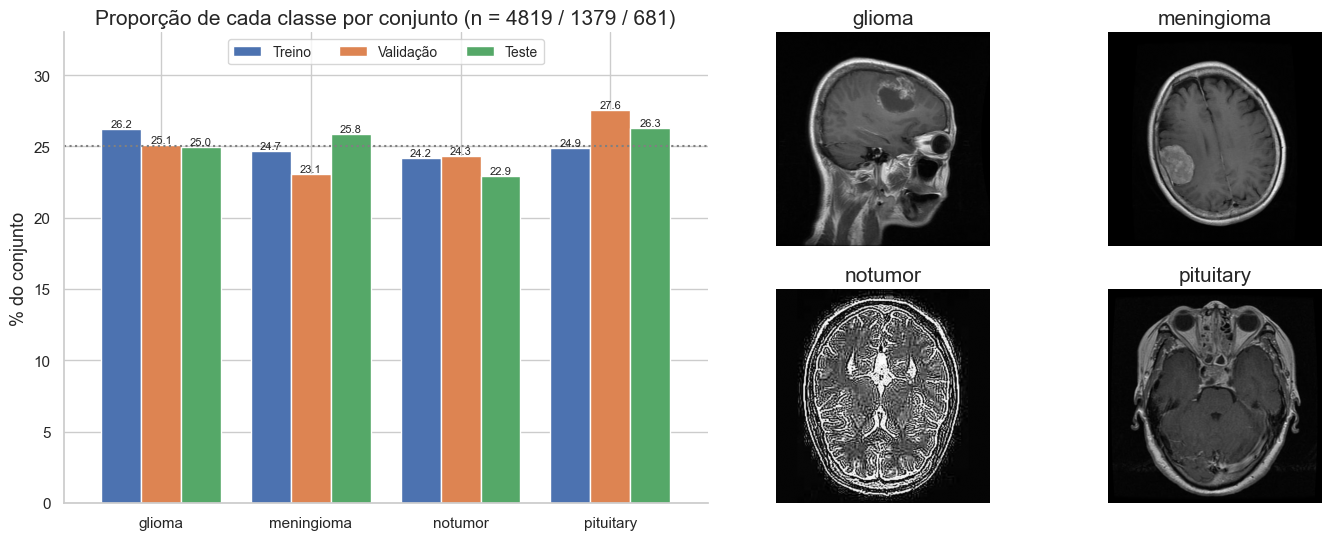

salvo: 01_dados.png


In [4]:
from scipy.stats import chi2_contingency
cnt = pd.DataFrame({NOME_S[s].capitalize(): np.bincount(Y[s], minlength=NC) for s in SPL3}, index=CLASSES); prop = cnt / cnt.sum()
chi2, p_chi, _, _ = chi2_contingency(cnt.values); maxdev = float(prop.sub(prop.mean(axis=1), axis=0).abs().values.max() * 100)
fig = plt.figure(figsize=(14, 5.6)); gs = fig.add_gridspec(2, 4); ax = fig.add_subplot(gs[:, :2])
(prop * 100).plot.bar(ax=ax, rot=0, color=["#4c72b0", "#dd8452", "#55a868"], width=.8); ax.axhline(100 / NC, color="gray", ls=":"); ax.set_ylabel("% do conjunto"); ax.set_ylim(0, 33)
ax.set_title(f"Proporção de cada classe por conjunto (n = {cnt.sum().iloc[0]} / {cnt.sum().iloc[1]} / {cnt.sum().iloc[2]})"); ax.legend(ncol=3, loc="upper center", fontsize=10)
for c_ in ax.containers: ax.bar_label(c_, fmt="%.1f", fontsize=8)
rng = np.random.default_rng(SEED)
for k, c in enumerate(CLASSES):
    a = fig.add_subplot(gs[k // 2, 2 + k % 2]); i = int(rng.choice(np.where(Y["test"] == k)[0])); a.imshow(Image.open(CAM["test"][i]).convert("L"), cmap="gray"); a.set_title(c); a.axis("off")
plt.tight_layout(); tot = cnt.sum()
NUM.update(imagens_treino=int(tot.iloc[0]), imagens_validacao=int(tot.iloc[1]), imagens_teste=int(tot.iloc[2]), chi2_p_estratificacao=round(float(p_chi), 3), maior_desvio_proporcao_pp=round(maxdev, 2), razao_maior_menor_classe_treino=round(cnt.iloc[:, 0].max() / cnt.iloc[:, 0].min(), 2))
reg_tab("01_dataset", cnt.assign(Total=cnt.sum(axis=1)), "Imagens por classe e conjunto")
salvar("01_dados.png", "Conjunto de dados: classes, divisão e exemplos",
       "Proporção de cada classe dentro de treino, validação e teste, o tamanho de cada conjunto e um exemplo de cada classe (512×512, tons de cinza).",
       "Barras de uma mesma classe com alturas parecidas nos três conjuntos indicam divisão estratificada; classes próximas de 25% indicam conjunto balanceado, caso em que a acurácia é uma métrica adequada.",
       f"{tot.sum()} imagens (Roboflow, CC BY 4.0): treino {NUM['imagens_treino']}, validação {NUM['imagens_validacao']}, teste {NUM['imagens_teste']}. A maior diferença de proporção entre conjuntos é {maxdev:.1f} p.p. (χ² p = {p_chi:.2f}: {'sem evidência de diferença' if p_chi > .05 else 'diferença estatística pequena'}). Razão entre a maior e a menor classe no treino: {NUM['razao_maior_menor_classe_treino']:.2f}.")

,Subconjunto,n,Acurácia
0,completo,681,0.9794
1,limpo (sem quase-duplicata),570,0.9772
2,só com quase-duplicata,111,0.9910


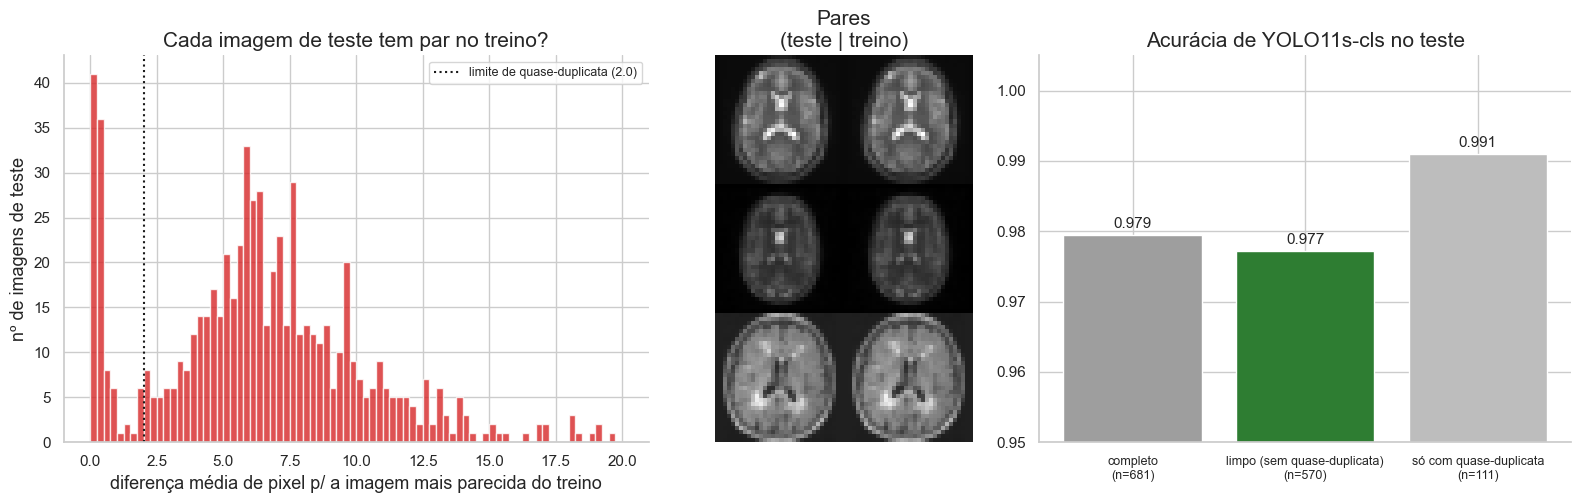

salvo: 02_vazamento_duplicatas.png


In [5]:
X32 = {s: np.stack([np.asarray(Image.open(p).convert("L").resize((32, 32), Image.BILINEAR), dtype=np.float32).ravel() for p in CAM[s]]) for s in SPL3}
def nn_dist(a, b): D = cdist(X32[a], X32[b], "cityblock") / 1024; return D.min(1), D.argmin(1)
nn_tt, j_tt = nn_dist("test", "train"); nn_tv, _ = nn_dist("test", "val"); nn_vt, _ = nn_dist("val", "train")
dup_tt, dup_tv, dup_vt = nn_tt <= DUP_LIM, nn_tv <= DUP_LIM, nn_vt <= DUP_LIM; LIMPO = ~(dup_tt | dup_tv)
rot_ok = float(np.mean([Y["test"][i] == Y["train"][j_tt[i]] for i in np.where(dup_tt)[0]])) if dup_tt.any() else np.nan
accs = {nome: (accuracy_score(Y["test"][mk], PRED["test"][mk]), int(mk.sum())) for nome, mk in (("completo", np.ones(len(Y["test"]), bool)), ("limpo (sem quase-duplicata)", LIMPO), ("só com quase-duplicata", ~LIMPO))}
fig, ax = plt.subplots(1, 3, figsize=(16, 5), gridspec_kw={"width_ratios": [1.1, .5, 1]})
ax[0].hist(nn_tt, bins=np.linspace(0, 20, 81), color="#d62728", alpha=.8); ax[0].axvline(DUP_LIM, color="k", ls=":", label=f"limite de quase-duplicata ({DUP_LIM})")
ax[0].set_xlabel("diferença média de pixel p/ a imagem mais parecida do treino"); ax[0].set_ylabel("nº de imagens de teste"); ax[0].set_title("Cada imagem de teste tem par no treino?"); ax[0].legend(fontsize=9)
ordem = np.argsort(nn_tt)[:3]; ax[1].imshow(np.concatenate([np.concatenate([X32["test"][i].reshape(32, 32), X32["train"][j_tt[i]].reshape(32, 32)], 1) for i in ordem], 0), cmap="gray"); ax[1].axis("off"); ax[1].set_title("Pares\n(teste | treino)")
nomes = list(accs); v = [accs[n][0] for n in nomes]; ax[2].bar(range(3), v, color=["#9e9e9e", "#2e7d32", "#bdbdbd"]); ax[2].set_xticks(range(3)); ax[2].set_xticklabels([f"{n}\n(n={accs[n][1]})" for n in nomes], fontsize=9)
ax[2].set_ylim(.95, 1.005); ax[2].set_title(f"Acurácia de {ALVO} no teste")
for i, x_ in enumerate(v): ax[2].text(i, x_ + .001, f"{x_:.3f}", ha="center", fontsize=11)
plt.tight_layout()
NUM.update(imagens_teste_quase_duplicata=int(dup_tt.sum()), pct_teste_quase_duplicata=round(100 * dup_tt.mean(), 1), pct_val_quase_duplicata=round(100 * dup_vt.mean(), 1), acc_teste_completo=round(accs["completo"][0], 4),
           acc_teste_limpo=round(accs["limpo (sem quase-duplicata)"][0], 4), n_teste_limpo=accs["limpo (sem quase-duplicata)"][1], acc_teste_so_duplicata=round(accs["só com quase-duplicata"][0], 4), rotulo_igual_no_par=round(rot_ok, 3))
reg_tab("02_duplicatas", pd.DataFrame({"Subconjunto": nomes, "n": [accs[n][1] for n in nomes], "Acurácia": v}), "Efeito das quase-duplicatas no teste", index=False)
salvar("02_vazamento_duplicatas.png", "Vazamento: imagens de teste quase idênticas às do treino",
       "Histograma da diferença de pixel entre cada imagem de teste e a mais parecida do treino (miniaturas 32×32), exemplos de pares e a acurácia do modelo no teste completo, no teste limpo (sem quase-duplicatas) e só nas imagens que têm par.",
       "O pico perto de 0 são imagens praticamente idênticas às do treino: vazamento. Se a acurácia no teste limpo for próxima à do completo, o vazamento inflou pouco o resultado.",
       f"{NUM['imagens_teste_quase_duplicata']} imagens de teste ({NUM['pct_teste_quase_duplicata']}%) têm quase-duplicata no treino (e {NUM['pct_val_quase_duplicata']}% da validação); o rótulo do par é o mesmo em {100*rot_ok:.0f}% dos casos. Acurácia de {ALVO}: {accs['completo'][0]:.3f} no teste completo, {accs['limpo (sem quase-duplicata)'][0]:.3f} no teste limpo ({accs['limpo (sem quase-duplicata)'][1]} imagens) e {accs['só com quase-duplicata'][0]:.3f} nas imagens com par.")

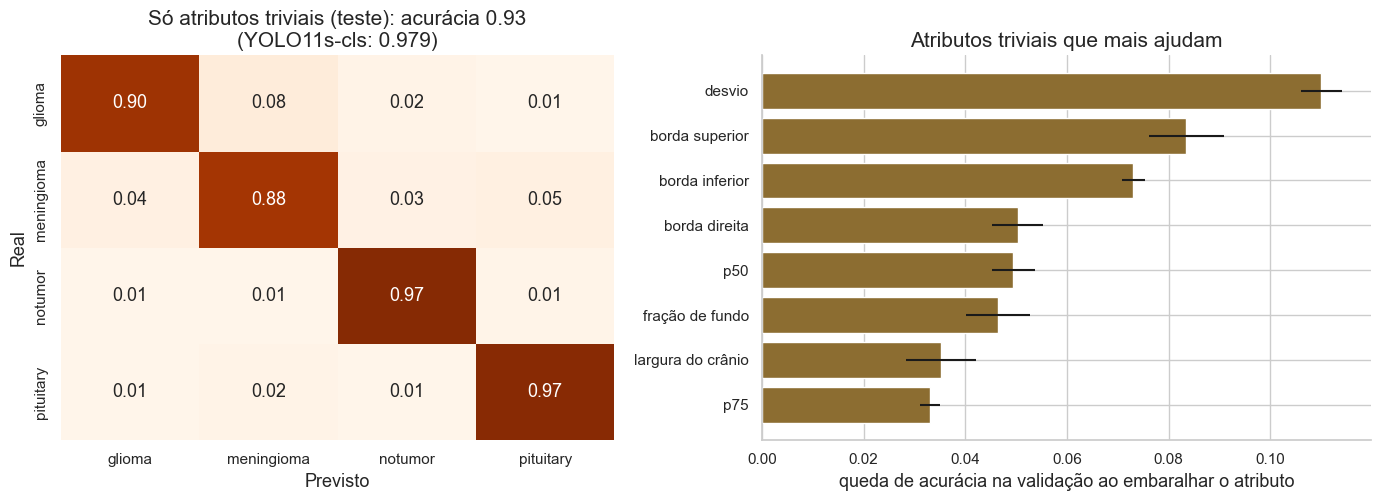

salvo: 03_auditoria_atalhos.png


In [6]:
FEATN = ["média", "desvio", "p5", "p25", "p50", "p75", "p95", "fração de fundo", "altura do crânio", "largura do crânio", "aspecto", "área ocupada", "borda superior", "borda inferior", "borda esquerda", "borda direita", "canto sup. esq.", "canto sup. dir."]
def feats(path):
    a = np.asarray(Image.open(path).convert("L").resize((256, 256), Image.BILINEAR), dtype=np.float32); fg = a > 8; ys, xs = np.where(fg)
    h, w = (ys.max() - ys.min() + 1, xs.max() - xs.min() + 1) if len(ys) else (0, 0)
    return [a.mean(), a.std(), *np.percentile(a, [5, 25, 50, 75, 95]), (~fg).mean(), h, w, w / max(h, 1), h * w / 65536, a[:8].mean(), a[-8:].mean(), a[:, :8].mean(), a[:, -8:].mean(), np.median(a[:16, :16]), np.median(a[:16, -16:])]
fp = CACHE / f"feats_{sum(len(DS[s]) for s in SPL3)}.npz"
if fp.exists(): FT = dict(np.load(fp))
else: FT = {s: np.array([feats(p) for p in CAM[s]]) for s in SPL3}; np.savez(fp, **FT)
hgb = HistGradientBoostingClassifier(max_iter=200, random_state=SEED).fit(FT["train"], Y["train"]); Ph = hgb.predict(FT["test"])
acc_h, acc_hv, acc_hl = accuracy_score(Y["test"], Ph), accuracy_score(Y["val"], hgb.predict(FT["val"])), accuracy_score(Y["test"][LIMPO], Ph[LIMPO])
pi = permutation_importance(hgb, FT["val"], Y["val"], n_repeats=5, random_state=SEED, scoring="accuracy"); ordem = np.argsort(-pi.importances_mean)[:8]
fig, ax = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1, 1.1]})
sns.heatmap(confusion_matrix(Y["test"], Ph, normalize="true"), annot=True, fmt=".2f", cmap="Oranges", vmin=0, vmax=1, xticklabels=CLASSES, yticklabels=CLASSES, ax=ax[0], cbar=False)
ax[0].set_title(f"Só atributos triviais (teste): acurácia {acc_h:.2f}\n({ALVO}: {acc('test'):.3f})"); ax[0].set_xlabel("Previsto"); ax[0].set_ylabel("Real")
ax[1].barh([FEATN[i] for i in ordem][::-1], pi.importances_mean[ordem][::-1], xerr=pi.importances_std[ordem][::-1], color="#8c6d31"); ax[1].set_xlabel("queda de acurácia na validação ao embaralhar o atributo"); ax[1].set_title("Atributos triviais que mais ajudam")
plt.tight_layout(); top3 = [FEATN[i] for i in ordem[:3]]
NUM.update(acc_atalhos_teste=round(acc_h, 4), acc_atalhos_val=round(acc_hv, 4), acc_atalhos_teste_limpo=round(acc_hl, 4), atalho_top1=top3[0], atalho_top2=top3[1], atalho_top3=top3[2], ganho_sobre_atalho_pp=round(100 * (acc("test") - acc_h), 1))
nivel = "alerta: há sinais fortes de atalhos de aquisição" if acc_h > CRIT["atalho_max"] else ("atenção: os atributos triviais já preveem acima do acaso" if acc_h > .4 else "sem sinal relevante de atalhos")
salvar("03_auditoria_atalhos.png", "Auditoria de atalhos: o que atributos triviais da imagem conseguem prever",
       "Matriz de confusão (teste) de um classificador que só enxerga 18 atributos triviais da imagem (brilho, contraste, fração de fundo preto, tamanho do crânio, bordas, cantos) e os atributos que mais pesam para ele.",
       "Se atributos que nada dizem sobre tumor preveem bem a classe, a origem/aquisição das imagens está correlacionada com o rótulo e um modelo profundo pode estar usando esse atalho. Perto de 25% (acaso) indica ausência de atalho simples.",
       f"O modelo de atalhos acerta {acc_h:.2f} no teste ({acc_hl:.2f} no teste limpo, {acc_hv:.2f} na validação), contra {1/NC:.2f} do acaso. Atributos mais úteis: {', '.join(top3)}. Leitura: {nivel}. Isso não prova que {ALVO} use esses atalhos, mas cerca de {100*acc_h:.0f}% da tarefa pode ser resolvida sem olhar a lesão: o ganho do modelo sobre o atalho é ≈{100*(acc('test')-acc_h):.0f} p.p. Validar em imagens de outra origem é o próximo passo.")

## 2. Treinamento
Histórico real do treino: loss de treino e validação por época, taxa de aprendizado (do YOLO: gravada em `results.csv`; da CNN: **reconstruída** pela fórmula do cosine, pois o treino não a gravou) e acurácia de validação. A **faixa de empate** é "melhor − 1 desvio" da fase final: o modelo está em platô a partir da primeira época que entra nela.

,valor
Épocas executadas,93.0000
Melhor época,63.0000
Acurácia de validação na melhor época,0.9710
Início do platô (época),49.0000
Otimismo da seleção (p.p.),0.3129
Menor loss de validação,0.1118
Loss de treino final,0.0137
LR inicial,0.0001
LR final,0.0000
Tempo de treino (min),801.2333


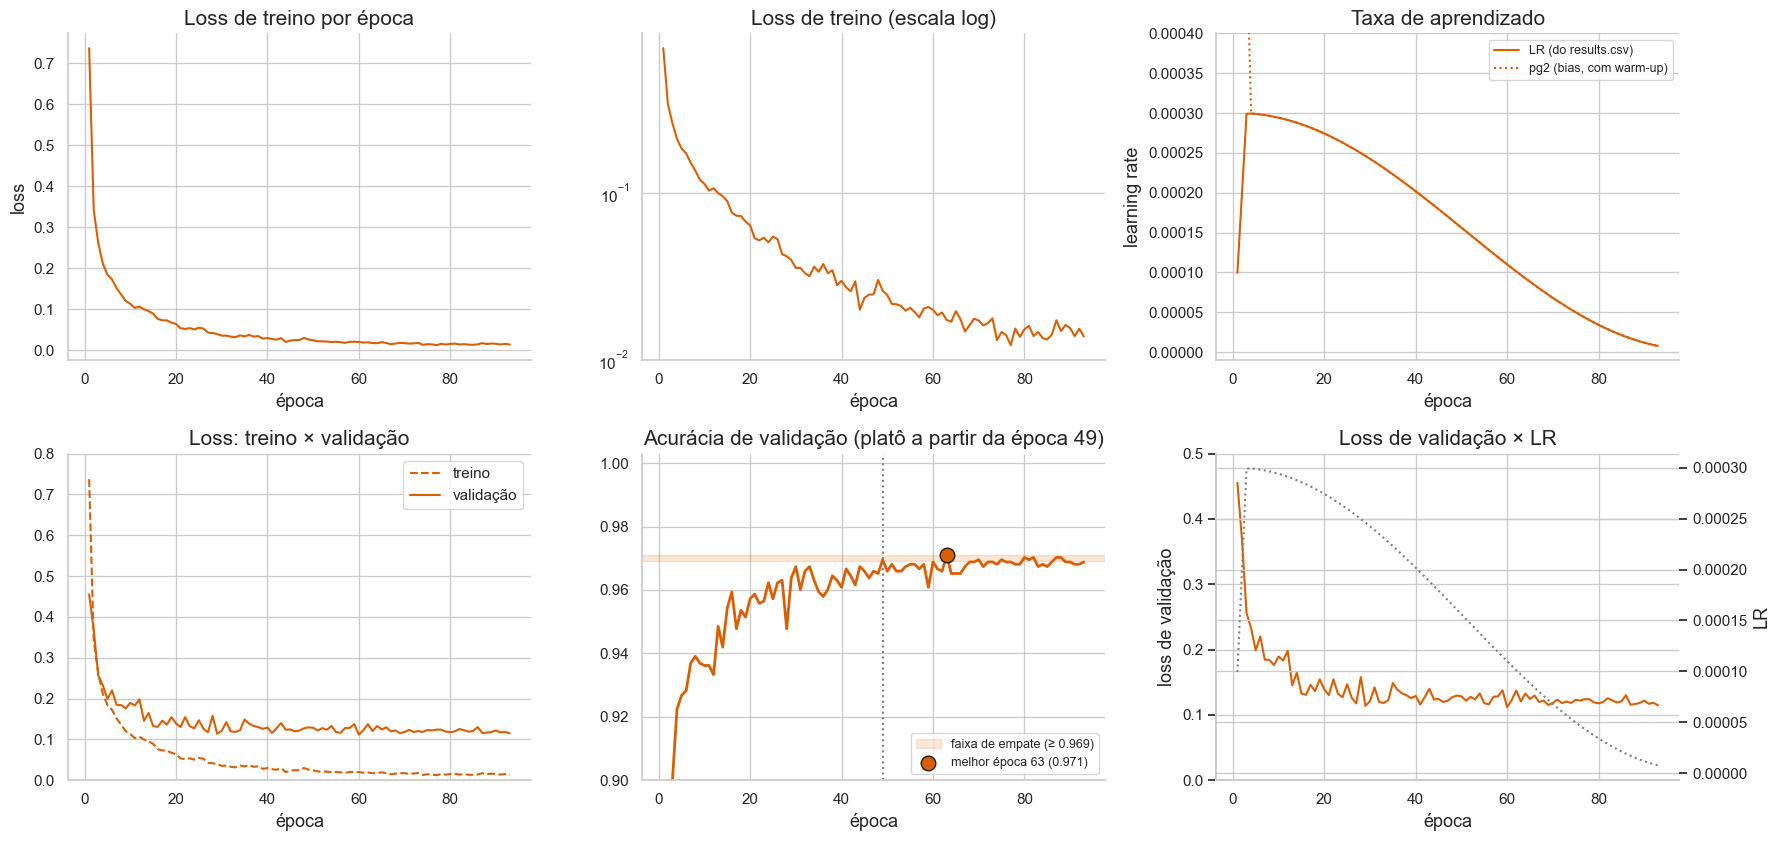

salvo: 04_treinamento.png


In [7]:
if EH_YOLO: ep, tl, vl, va, lr, tr = hist_y["epoch"].values, hist_y["train/loss"].values, hist_y["val/loss"].values, hist_y["metrics/accuracy_top1"].values, hist_y["lr/pg0"].values, None
else: ep, tl, vl, va, lr, tr = hist_c["epoca"].values, hist_c["loss_treino"].values, hist_c["loss_val"].values, hist_c["acc_val"].values, hist_c["lr"].values, hist_c["acc_treino"].values
late = va[len(va) // 2:]; sd_late = late.std(ddof=1); b = int(va.argmax()); best = va[b]; faixa = best - sd_late; plato = int(ep[va >= faixa].min()); otim = best - late.mean()
fig, ax = plt.subplots(2, 3, figsize=(18, 8.6))
ax[0, 0].plot(ep, tl, color=COR); ax[0, 0].set_title("Loss de treino por época"); ax[0, 0].set_xlabel("época"); ax[0, 0].set_ylabel("loss")
ax[0, 1].plot(ep, tl, color=COR); ax[0, 1].set_yscale("log"); ax[0, 1].set_title("Loss de treino (escala log)"); ax[0, 1].set_xlabel("época")
ax[0, 2].plot(ep, lr, color=COR, label="LR (do results.csv)" if EH_YOLO else f"LR (reconstruído, cosine T_max={TMAX})")
if EH_YOLO: ax[0, 2].plot(ep, hist_y["lr/pg2"].values, color=COR, ls=":", label="pg2 (bias, com warm-up)"); ax[0, 2].set_ylim(-1e-5, 4e-4)
ax[0, 2].set_title("Taxa de aprendizado"); ax[0, 2].set_xlabel("época"); ax[0, 2].set_ylabel("learning rate"); ax[0, 2].legend(fontsize=9)
ax[1, 0].plot(ep, tl, "--", color=COR, label="treino"); ax[1, 0].plot(ep, vl, color=COR, label="validação"); ax[1, 0].set_ylim(0, .8); ax[1, 0].set_title("Loss: treino × validação"); ax[1, 0].set_xlabel("época"); ax[1, 0].legend()
ax[1, 1].plot(ep, va, color=COR, lw=2); ax[1, 1].axhspan(faixa, best, color=COR, alpha=.15, label=f"faixa de empate (≥ {faixa:.3f})"); ax[1, 1].scatter([ep[b]], [best], s=110, color=COR, edgecolor="k", zorder=5, label=f"melhor época {ep[b]} ({best:.3f})")
ax[1, 1].axvline(plato, color="gray", ls=":"); ax[1, 1].set_ylim(.9, 1.003); ax[1, 1].set_title(f"Acurácia de validação (platô a partir da época {plato})"); ax[1, 1].set_xlabel("época"); ax[1, 1].legend(fontsize=9, loc="lower right")
a2 = ax[1, 2]; a3 = a2.twinx(); a2.plot(ep, vl, color=COR); a3.plot(ep, lr, color="gray", ls=":"); a2.set_ylim(0, .5); a2.set_xlabel("época"); a2.set_ylabel("loss de validação"); a3.set_ylabel("LR"); a2.set_title("Loss de validação × LR")
plt.tight_layout()
tempo = hist_y["time"].iloc[-1] / 60 if EH_YOLO else meta["tempo_treino_min"]; sobe = int(((tl[1:] / tl[:-1] > 1.3) & (tl[1:] - tl[:-1] > .02)).sum())
NUM.update(epocas=int(len(ep)), melhor_epoca=int(ep[b]), acc_val_melhor_epoca=round(float(best), 4), plato_inicio=plato, otimismo_selecao_pp=round(100 * otim, 2), tempo_treino_min=round(float(tempo), 1), loss_treino_final=round(float(tl[-1]), 4), loss_val_final=round(float(vl[-1]), 4), epocas_loss_sobe30=sobe,
           lr_inicial=float(lr[0]), lr_final=float(lr[-1]), parou_early_stopping=bool(len(ep) < args_y["epochs"]) if EH_YOLO else None)
reg_tab("03_resumo_treino", pd.Series({"Épocas executadas": len(ep), "Melhor época": int(ep[b]), "Acurácia de validação na melhor época": float(best), "Início do platô (época)": plato, "Otimismo da seleção (p.p.)": 100 * otim,
        "Menor loss de validação": float(vl.min()), "Loss de treino final": float(tl[-1]), "LR inicial": float(lr[0]), "LR final": float(lr[-1]), "Tempo de treino (min)": float(tempo)}, name="valor").to_frame(), "Resumo do treinamento")
salvar("04_treinamento.png", "Treinamento: loss, taxa de aprendizado e acurácia de validação",
       "Loss de treino (linear e log), taxa de aprendizado por época, loss de treino × validação, acurácia de validação com a faixa de empate e a melhor época, e a loss de validação sobreposta ao LR.",
       "Loss de treino caindo sem picos indica otimização estável. Loss de validação que se estabiliza (sem subir) indica ausência de sobreajuste acentuado. O pico da validação não decide sozinho: dentro da faixa de empate o ponto mais cedo é equivalente.",
       f"{len(ep)} épocas, melhor na {ep[b]}ª (validação {best:.4f}); platô a partir da época {plato}; otimismo da escolha da melhor época ≈ {100*otim:.2f} p.p. (melhor valor menos a média da fase final). Picos da loss de treino (alta de mais de 30% e de mais de 0,02 entre épocas): {sobe}. Tempo de treino {tempo:.0f} min" + (" (CPU)." if EH_YOLO else " (hardware não registrado) e LR reconstruído por fórmula."))

### Acurácia por época: treino × validação
Evolução da **acurácia de treino e de validação a cada época**. A diferença entre as duas é o gap de generalização: se a de treino sobe e a de validação fica para trás, há sobreajuste. Observação importante: a acurácia de treino por época do histórico é medida **durante o treino** (com augmentation e dropout ligados), por isso fica abaixo da medida depois do treino em modo inferência. A linha tracejada é a acurácia de treino do melhor checkpoint, medida agora sem augmentation.

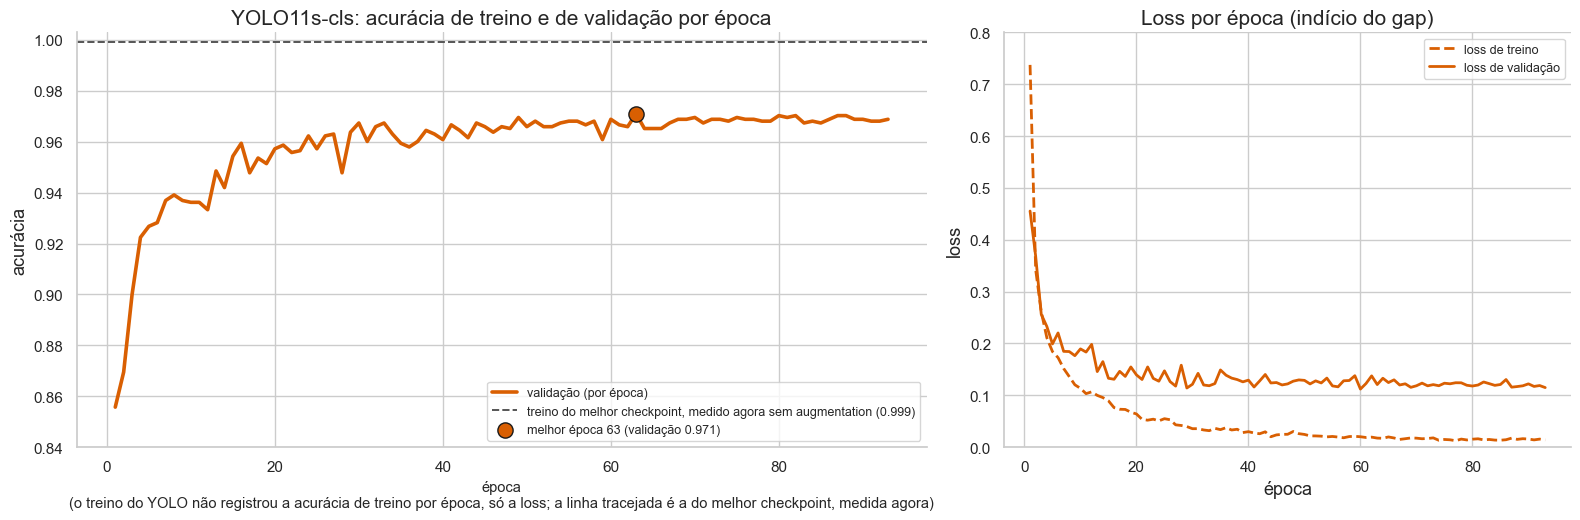

salvo: 05_acuracia_por_epoca.png


In [8]:
acc_tr_ckpt = acc("train")
fig, ax = plt.subplots(1, 2, figsize=(16, 5.4), gridspec_kw={"width_ratios": [1.5, 1]})
ax[0].plot(ep, va, color=COR, lw=2.6, label="validação (por época)")
if tr is not None:
    ax[0].plot(ep, tr, color=COR, ls=":", lw=2.6, label="treino (por época; com augmentation e dropout)"); ax[0].fill_between(ep, va, tr, color=COR, alpha=.12)
ax[0].axhline(acc_tr_ckpt, color="#555", ls="--", lw=1.4, label=f"treino do melhor checkpoint, medido agora sem augmentation ({acc_tr_ckpt:.3f})")
ax[0].scatter([ep[b]], [va[b]], s=120, color=COR, edgecolor="k", zorder=5, label=f"melhor época {ep[b]} (validação {va[b]:.3f})")
ax[0].set_ylim(.6 if tr is not None else .84, 1.003); ax[0].set_xlabel("época" if tr is not None else "época\n(o treino do YOLO não registrou a acurácia de treino por época, só a loss; a linha tracejada é a do melhor checkpoint, medida agora)", fontsize=12 if tr is not None else 10.5); ax[0].set_ylabel("acurácia"); ax[0].set_title(f"{ALVO}: acurácia de treino e de validação por época"); ax[0].legend(loc="lower right", fontsize=9)
if tr is None:
    ax[1].plot(ep, tl, "--", color=COR, lw=2, label="loss de treino"); ax[1].plot(ep, vl, color=COR, lw=2, label="loss de validação"); ax[1].set_ylim(0, .8); ax[1].set_ylabel("loss"); ax[1].set_title("Loss por época (indício do gap)"); ax[1].legend(fontsize=9)
else:
    gap_ep = 100 * (tr - va); ax[1].plot(ep, gap_ep, color=COR, lw=2); ax[1].axhline(0, color="gray", lw=.8); ax[1].axhline(100 * CRIT["gap_treino_val_max"], color="red", ls=":", label=f"limite do checklist ({100*CRIT['gap_treino_val_max']:.0f} p.p.)")
    ax[1].set_ylim(-4, 4); ax[1].text(.97, .05, f"nas primeiras épocas o gap é negativo (até {gap_ep.min():.0f} p.p.):\nbackbone congelado e augmentation ligados no treino", transform=ax[1].transAxes, ha="right", fontsize=9, bbox=dict(fc="white", ec="#aaa"))
    ax[1].set_ylabel("treino − validação (p.p.)"); ax[1].set_title("Gap de acurácia por época (eixo cortado em ±4)"); ax[1].legend(fontsize=9, loc="upper right")
ax[1].set_xlabel("época"); plt.tight_layout()
if tr is not None:
    g10 = float(np.mean(100 * (tr[-10:] - va[-10:]))); gmax = float((100 * (tr - va)).max()); emax = int(ep[int((tr - va).argmax())])
    NUM.update(gap_epoca_medio_ultimas10_pp=round(g10, 2), gap_epoca_max_pp=round(gmax, 2), epoca_gap_max=emax, acc_treino_ultima_epoca=round(float(tr[-1]), 4))
    res_txt = f"A acurácia de treino por época chega a {tr[-1]:.4f} na última época, contra {va[-1]:.4f} na validação. O gap médio nas últimas 10 épocas é {g10:.2f} p.p. (máximo de {gmax:.2f} p.p. na época {emax}), abaixo do limite de {100*CRIT['gap_treino_val_max']:.0f} p.p. do checklist. Medida agora, sem augmentation, a acurácia de treino do melhor checkpoint é {acc_tr_ckpt:.4f}."
else:
    gck = 100 * (acc_tr_ckpt - va[b])
    NUM.update(acc_treino_checkpoint=round(float(acc_tr_ckpt), 4), gap_checkpoint_pp=round(float(gck), 2), acc_treino_por_epoca_disponivel=False)
    res_txt = f"O treino do YOLO não gravou a acurácia de treino por época, então só a validação aparece como curva (de {va[0]:.3f} na época 1 a {best:.3f} na melhor época, {ep[b]}). A acurácia de treino do melhor checkpoint, medida agora sem augmentation, é {acc_tr_ckpt:.4f}: gap de {gck:.2f} p.p. em relação à validação. As losses (painel direito) mostram o mesmo padrão: a de treino continua caindo e a de validação se estabiliza. Para obter a curva completa seria preciso retreinar registrando a métrica (≈13 h em CPU)."
salvar("05_acuracia_por_epoca.png", f"Acurácia de treino e de validação por época — {ALVO}",
       "A acurácia de validação a cada época" + (" e a de treino registrada pelo próprio treinamento, com o gap entre as duas." if tr is not None else ", a acurácia de treino do melhor checkpoint medida agora e as losses de treino e validação (o treino do YOLO não registrou a acurácia de treino por época)."),
       "Treino subindo e validação ficando para trás indica sobreajuste (variância alta); as duas curvas próximas e estáveis indicam boa generalização. A acurácia de treino por época é medida com augmentation e dropout ligados, por isso fica um pouco abaixo da medida em modo inferência.",
       res_txt)

## 3. Desempenho por conjunto e diagnóstico de variância
Métricas em treino, validação e teste. **Treino ≫ validação** indica sobreajuste (variância alta); **validação ≈ teste** indica que a escolha do melhor epoch não "vazou" para o teste. O treino é medido em modo de inferência (sem augmentation). As barras trazem o intervalo de Wilson de 95%.

,treino,validação,teste
Acurácia,0.9994,0.9710,0.9794
Acurácia balanceada,0.9994,0.9703,0.9796
Precisão macro,0.9994,0.9707,0.9792
Recall macro,0.9994,0.9703,0.9796
F1 macro,0.9994,0.9703,0.9794
MCC,0.9992,0.9614,0.9726
Kappa,0.9992,0.9613,0.9726
AUC macro (OvR),1.0000,0.9966,0.9984
AP macro,1.0000,0.9923,0.9959
Log-loss,0.0094,0.1218,0.0780


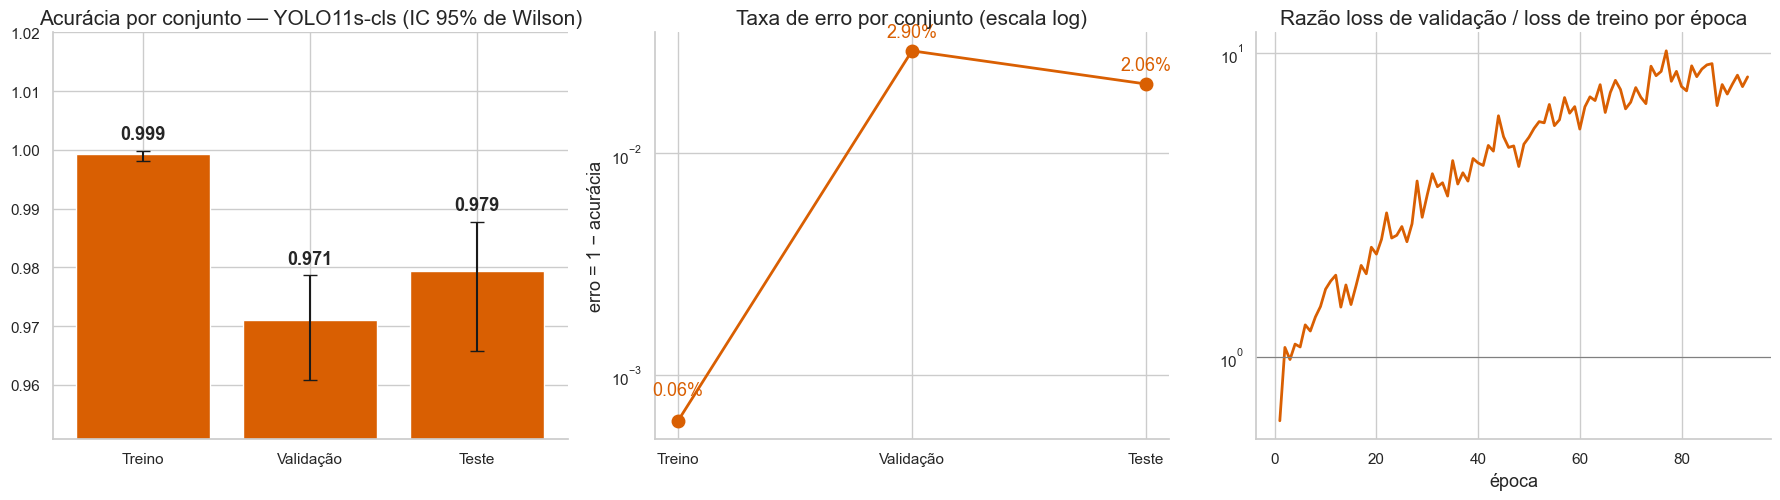

salvo: 06_desempenho_variancia.png


In [9]:
MET = pd.DataFrame({NOME_S[s]: metricas(Y[s], PROB[s]) for s in SPL3}); reg_tab("04_metricas", MET, "Métricas por conjunto")
d = []
for s in SPL3: k = int((PRED[s] == Y[s]).sum()); n = len(Y[s]); lo, hi = wilson(k, n); d.append((NOME_S[s].capitalize(), k / n, lo, hi))
d = pd.DataFrame(d, columns=["c", "a", "lo", "hi"]); g_tv, g_vt = acc("train") - acc("val"), acc("val") - acc("test")
fig, ax = plt.subplots(1, 3, figsize=(18, 5.2))
ax[0].bar(d["c"], d["a"], color=COR, yerr=[d["a"] - d["lo"], d["hi"] - d["a"]], capsize=5)
for i, (hi, v) in enumerate(zip(d["hi"], d["a"])): ax[0].text(i, hi + .002, f"{v:.3f}", ha="center", fontweight="bold")
ax[0].set_ylim(max(.9, d["lo"].min() - .01), 1.02); ax[0].set_title(f"Acurácia por conjunto — {ALVO} (IC 95% de Wilson)")
ax[1].plot(d["c"], 1 - d["a"], "o-", color=COR, lw=2, ms=9); ax[1].set_yscale("log"); ax[1].set_ylabel("erro = 1 − acurácia"); ax[1].set_title("Taxa de erro por conjunto (escala log)")
for i, v in enumerate(1 - d["a"]): ax[1].text(i, v * 1.15 + 1e-4, f"{100*v:.2f}%", ha="center", color=COR)
if tr is not None:
    ax[2].plot(ep, tr, ":", color=COR, lw=2, label="treino (com augmentation)"); ax[2].plot(ep, va, color=COR, lw=2, label="validação"); ax[2].fill_between(ep, va, tr, color=COR, alpha=.15); ax[2].set_ylim(.6, 1.003); ax[2].set_title("Acurácia de treino × validação por época"); ax[2].legend(loc="lower right")
else:
    ax[2].plot(ep, vl / tl, color=COR, lw=2); ax[2].axhline(1, color="gray", lw=.8); ax[2].set_yscale("log"); ax[2].set_title("Razão loss de validação / loss de treino por época")
ax[2].set_xlabel("época"); plt.tight_layout()
p1, n1, p2, n2 = acc("val"), len(Y["val"]), acc("test"), len(Y["test"]); pp_ = (p1 * n1 + p2 * n2) / (n1 + n2); z = (p1 - p2) / math.sqrt(pp_ * (1 - pp_) * (1 / n1 + 1 / n2)); pz = 2 * (1 - norm.cdf(abs(z)))
diag = "variância alta (sobreajuste)" if g_tv > .05 else ("variância moderada" if g_tv > CRIT["gap_treino_val_max"] else "variância baixa")
NUM.update(acc_treino=round(acc("train"), 4), acc_val=round(acc("val"), 4), acc_teste=round(acc("test"), 4), gap_treino_val_pp=round(100 * g_tv, 2), gap_val_teste_pp=round(100 * g_vt, 2), p_val_vs_teste=round(float(pz), 3), diagnostico_variancia=diag,
           f1_macro_teste=round(MET.loc["F1 macro", "teste"], 4), mcc_teste=round(MET.loc["MCC", "teste"], 4), erros_teste=int(MET.loc["Erros (nº)", "teste"]), erros_val=int(MET.loc["Erros (nº)", "validação"]), acc_balanceada_teste=round(MET.loc["Acurácia balanceada", "teste"], 4))
salvar("06_desempenho_variancia.png", "Desempenho em treino, validação e teste e diagnóstico de variância",
       "Acurácia em cada conjunto com intervalo de confiança, taxa de erro em escala log e, abaixo, a evolução do gap de generalização (acurácia treino × validação no caso da CNN, razão entre as losses no caso do YOLO).",
       "Treino muito acima da validação indica sobreajuste. Validação próxima do teste indica estimativa estável. Intervalos que se sobrepõem indicam diferenças que podem ser ruído amostral.",
       f"Acurácia: treino {acc('train'):.4f}, validação {acc('val'):.4f}, teste {acc('test'):.4f} ({NUM['erros_teste']} erros em {n2} imagens). Gap treino−validação {100*g_tv:.2f} p.p. ({diag}); validação−teste {100*g_vt:+.2f} p.p. (p = {pz:.2f}: {'diferença significativa' if pz < .05 else 'compatível com ruído amostral'}). F1 macro no teste {NUM['f1_macro_teste']:.4f}, MCC {NUM['mcc_teste']:.4f}.")

## 4. Matrizes de confusão e métricas por classe

,Conjunto,Classe,Precisão,Recall,F1,Suporte
0,validação,glioma,0.9443,0.9798,0.9617,346
1,validação,meningioma,0.9674,0.9340,0.9504,318
2,validação,notumor,0.9765,0.9910,0.9837,335
3,validação,pituitary,0.9946,0.9763,0.9854,380
4,teste,glioma,0.9709,0.9824,0.9766,170
5,teste,meningioma,0.9769,0.9602,0.9685,176
6,teste,notumor,0.9747,0.9872,0.9809,156
7,teste,pituitary,0.9944,0.9888,0.9916,179


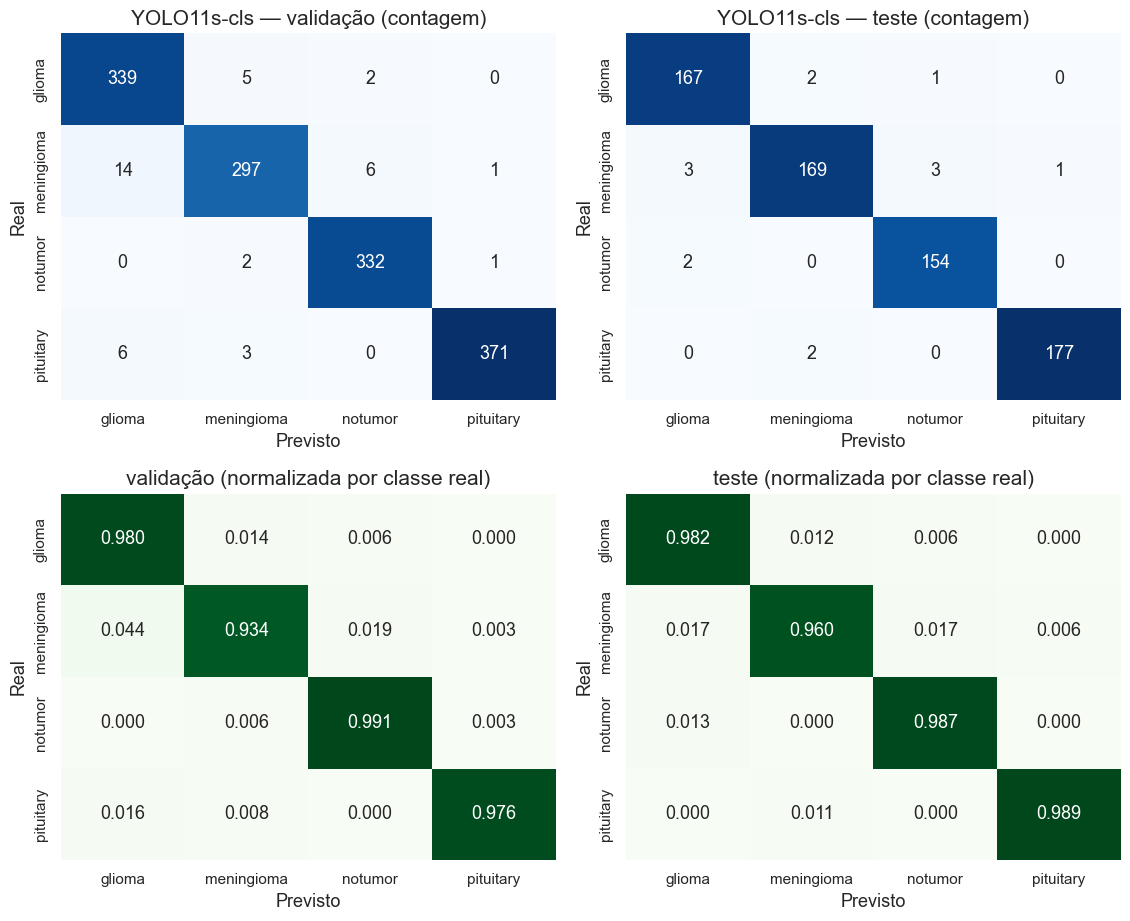

salvo: 07_matrizes_confusao.png


In [10]:
fig, ax = plt.subplots(2, 2, figsize=(11.5, 9.4)); linhas = []
for j, s in enumerate(SV):
    cm = confusion_matrix(Y[s], PRED[s]); cmn = cm / cm.sum(1, keepdims=True)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=ax[0, j], cbar=False); ax[0, j].set_title(f"{ALVO} — {NOME_S[s]} (contagem)")
    sns.heatmap(cmn, annot=True, fmt=".3f", cmap="Greens", vmin=0, vmax=1, xticklabels=CLASSES, yticklabels=CLASSES, ax=ax[1, j], cbar=False); ax[1, j].set_title(f"{NOME_S[s]} (normalizada por classe real)")
    for a in ax[:, j]: a.set_xlabel("Previsto"); a.set_ylabel("Real")
    pr, rc, f1 = (f(Y[s], PRED[s], average=None) for f in (precision_score, recall_score, f1_score))
    for i, c in enumerate(CLASSES): linhas.append(dict(Conjunto=NOME_S[s], Classe=c, Precisão=pr[i], Recall=rc[i], F1=f1[i], Suporte=int((Y[s] == i).sum())))
plt.tight_layout(); PC = pd.DataFrame(linhas)
cm = confusion_matrix(Y["test"], PRED["test"]).copy(); np.fill_diagonal(cm, 0); pares = sorted([(CLASSES[i], CLASSES[j], int(cm[i, j])) for i in range(NC) for j in range(NC) if cm[i, j]], key=lambda t: -t[2])[:4]
pt_ = PC[PC["Conjunto"] == "teste"]; pior = pt_.loc[pt_["Recall"].idxmin()]
NUM.update(menor_recall_classe=round(float(pior["Recall"]), 4), classe_menor_recall=str(pior["Classe"]), confusao_mais_comum=f"{pares[0][0]}→{pares[0][1]} ({pares[0][2]})" if pares else "nenhuma")
reg_tab("05_por_classe", PC, "Precisão, recall e F1 por classe", index=False)
salvar("07_matrizes_confusao.png", "Matrizes de confusão em validação e teste",
       "Quantas imagens de cada classe real foram previstas como cada classe (contagem e % da linha) em validação e teste.",
       "A diagonal são os acertos; quanto mais escura a diagonal e mais clara a parte de fora, melhor. Cada célula fora da diagonal mostra qual classe é confundida com qual.",
       f"Erros: {NUM['erros_val']} na validação e {NUM['erros_teste']} no teste. Confusões mais frequentes no teste (real → previsto): " + "; ".join(f"{a}→{b} ({n})" for a, b, n in pares) + f". Pior recall por classe no teste: {pior['Classe']} ({pior['Recall']:.3f}).")

,Treino,Validação,Teste
glioma,1.0000,0.9798,0.9824
meningioma,0.9983,0.9340,0.9602
notumor,1.0000,0.9910,0.9872
pituitary,0.9992,0.9763,0.9888


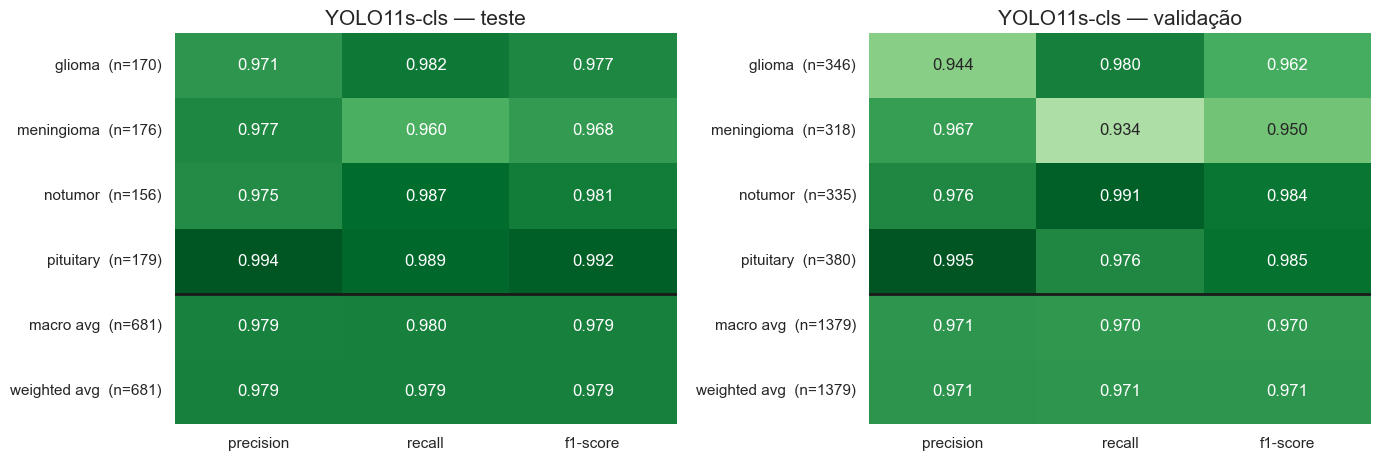

salvo: 08_relatorio_classificacao.png


In [11]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
for a, s in zip(ax, ["test", "val"]):
    r = classification_report(Y[s], PRED[s], target_names=CLASSES, output_dict=True, digits=4); t = pd.DataFrame({k: r[k] for k in CLASSES + ["macro avg", "weighted avg"]}).T[["precision", "recall", "f1-score", "support"]]
    lab = t[["precision", "recall", "f1-score"]].map(lambda v: f"{v:.3f}").values
    sns.heatmap(t[["precision", "recall", "f1-score"]], annot=lab, fmt="", cmap="Greens", vmin=.9, vmax=1, ax=a, cbar=False, annot_kws={"size": 12}); a.axhline(NC, color="k", lw=2)
    a.set_yticklabels([f"{n}  (n={int(x)})" for n, x in zip(t.index, t["support"])], rotation=0); a.set_title(f"{ALVO} — {NOME_S[s]}")
plt.tight_layout(); rcs = pd.DataFrame({NOME_S[s].capitalize(): recall_score(Y[s], PRED[s], average=None) for s in SPL3}, index=CLASSES)
reg_tab("06_recall_por_classe_conjunto", rcs, "Recall por classe em cada conjunto")
yt = Y["test"] != i_nt; ptt = PRED["test"] != i_nt; tn_, fp_ = int((~yt & ~ptt).sum()), int((~yt & ptt).sum())
NUM.update(f2_tumor=round(fbeta_score(yt, ptt, beta=2), 4), especificidade=round(tn_ / (tn_ + fp_), 4), sensibilidade_tumor=round(recall_score(yt, ptt), 4), precisao_tumor=round(precision_score(yt, ptt), 4))
salvar("08_relatorio_classificacao.png", "Relatório de classificação por classe (precisão, recall e F1)",
       "Precisão, recall e F1 de cada classe no teste e na validação, com as médias macro (cada classe pesa igual) e ponderada pelo número de imagens (suporte).",
       "A linha de cada classe mostra onde o modelo é mais fraco; a média macro dá voz à classe mais difícil e a ponderada se aproxima da acurácia. Verde mais escuro = melhor.",
       f"No teste: F1 macro {NUM['f1_macro_teste']:.4f}; pior recall {NUM['menor_recall_classe']:.3f} ({NUM['classe_menor_recall']}). Na visão tumor × sem tumor: sensibilidade {NUM['sensibilidade_tumor']:.3f}, especificidade {NUM['especificidade']:.3f}, precisão {NUM['precisao_tumor']:.3f} e F2 {NUM['f2_tumor']:.3f}.")

## 5. Curvas ROC e Precisão-Recall
A **ROC** (por classe, um-contra-todos) mostra recall (TPR) contra falso alarme (FPR) ao variar o limiar; **AUC = 1** é separação perfeita e 0,5 é acaso. A curva **Precisão-Recall** é mais exigente com classes raras. Como o modelo está perto de 1, cada curva aparece completa e em zoom.

,Conjunto,Classe,AUC,AP
0,validação,glioma,0.9972,0.9931
1,validação,meningioma,0.9901,0.9787
2,validação,notumor,0.9996,0.9988
3,validação,pituitary,0.9994,0.9986
4,teste,glioma,0.9974,0.9954
5,teste,meningioma,0.9971,0.9908
6,teste,notumor,0.9999,0.9996
7,teste,pituitary,0.9991,0.9979


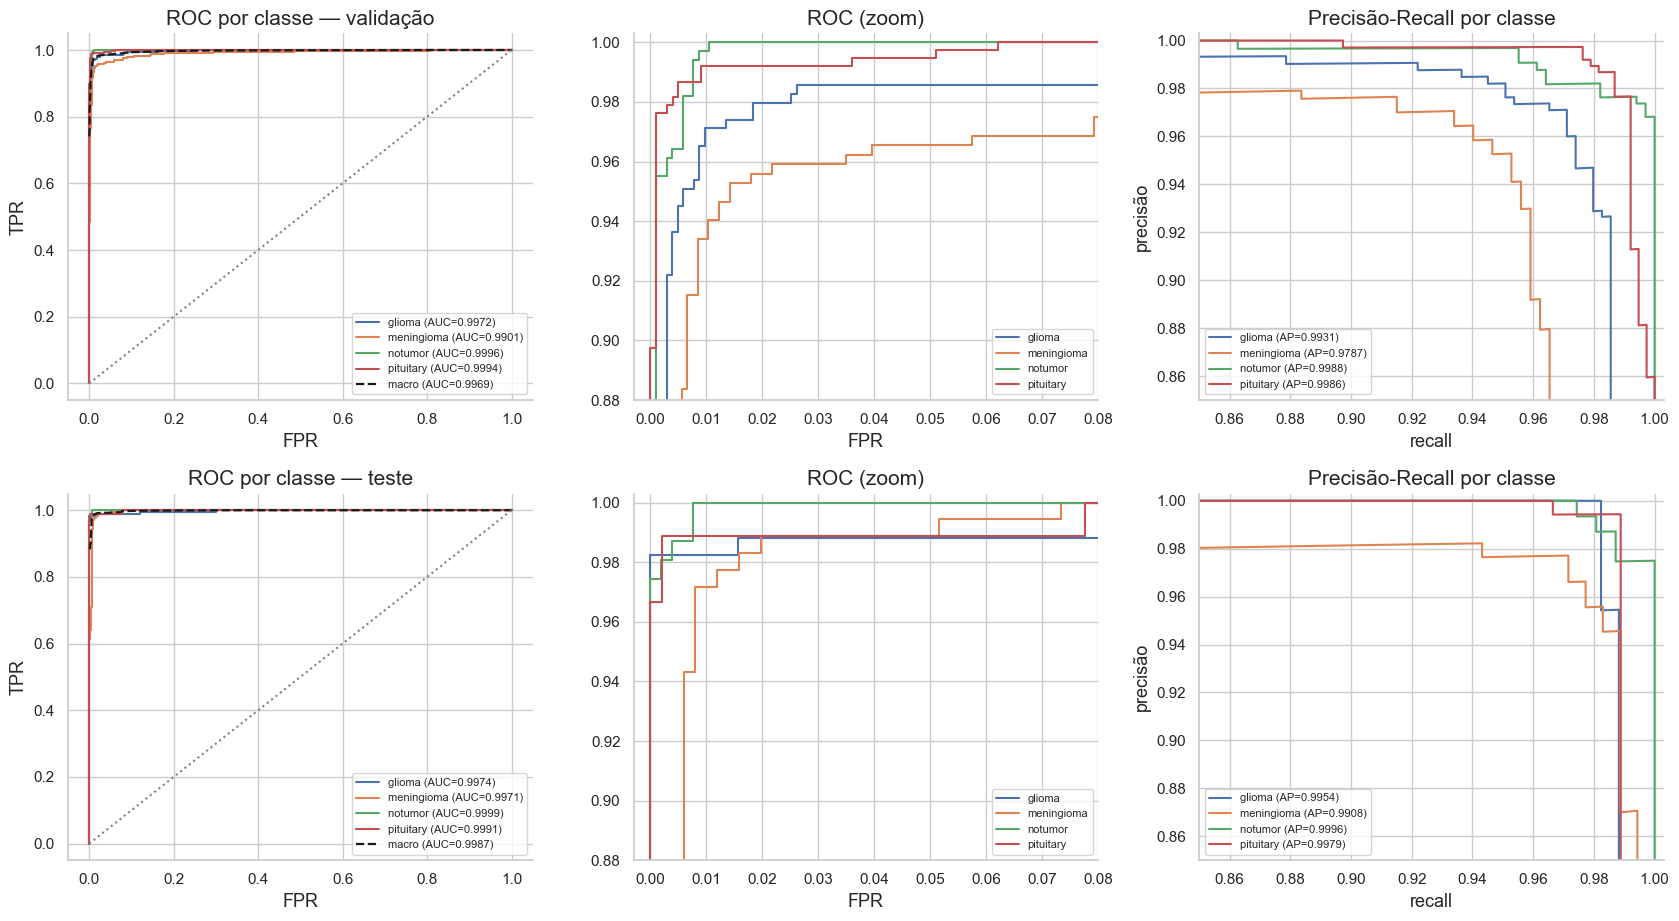

salvo: 09_roc_pr.png


In [12]:
fig, ax = plt.subplots(len(SV), 3, figsize=(17, 4.7 * len(SV))); Yb = {s: np.eye(NC)[Y[s]] for s in SV}; linhas = []
for r, s in enumerate(SV):
    for i, c in enumerate(CLASSES):
        fpr, tpr, _ = roc_curve(Yb[s][:, i], PROB[s][:, i]); a_ = roc_auc_score(Yb[s][:, i], PROB[s][:, i]); ap = average_precision_score(Yb[s][:, i], PROB[s][:, i]); linhas.append(dict(Conjunto=NOME_S[s], Classe=c, AUC=a_, AP=ap))
        ax[r, 0].plot(fpr, tpr, label=f"{c} (AUC={a_:.4f})"); ax[r, 1].plot(fpr, tpr, label=c); pr_, rc_, _ = precision_recall_curve(Yb[s][:, i], PROB[s][:, i]); ax[r, 2].plot(rc_, pr_, label=f"{c} (AP={ap:.4f})")
    fm, tm, am = roc_macro(Y[s], PROB[s]); ax[r, 0].plot(fm, tm, "k--", lw=1.6, label=f"macro (AUC={am:.4f})"); ax[r, 0].plot([0, 1], [0, 1], ":", color="gray")
    ax[r, 0].set_title(f"ROC por classe — {NOME_S[s]}"); ax[r, 0].set_xlabel("FPR"); ax[r, 0].set_ylabel("TPR"); ax[r, 0].legend(fontsize=8, loc="lower right")
    ax[r, 1].set_xlim(-.003, .08); ax[r, 1].set_ylim(.88, 1.003); ax[r, 1].set_title("ROC (zoom)"); ax[r, 1].set_xlabel("FPR"); ax[r, 1].legend(fontsize=8, loc="lower right")
    ax[r, 2].set_xlim(.85, 1.003); ax[r, 2].set_ylim(.85, 1.003); ax[r, 2].set_title("Precisão-Recall por classe"); ax[r, 2].set_xlabel("recall"); ax[r, 2].set_ylabel("precisão"); ax[r, 2].legend(fontsize=8, loc="lower left")
plt.tight_layout(); AU = pd.DataFrame(linhas); reg_tab("07_auc_ap_por_classe", AU, "AUC e AP por classe", index=False)
am_t, ap_t = MET.loc["AUC macro (OvR)", "teste"], MET.loc["AP macro", "teste"]; piorc = AU[AU["Conjunto"] == "teste"].loc[AU[AU["Conjunto"] == "teste"]["AUC"].idxmin()]
NUM.update(auc_macro_teste=round(am_t, 4), ap_macro_teste=round(ap_t, 4), auc_macro_val=round(MET.loc["AUC macro (OvR)", "validação"], 4), menor_auc_classe=round(float(piorc["AUC"]), 4), classe_menor_auc=str(piorc["Classe"]))
salvar("09_roc_pr.png", "Curvas ROC e Precisão-Recall por classe",
       "ROC de cada classe (um-contra-todos) com a média macro, a mesma curva em zoom no canto de interesse e a curva Precisão-Recall de cada classe, em validação e teste.",
       "Quanto mais a ROC colar no canto superior esquerdo, melhor (AUC 1,0 = separação perfeita); quanto mais a curva PR ficar no canto superior direito, melhor. Curvas das classes sobrepostas indicam desempenho uniforme.",
       f"AUC macro: {NUM['auc_macro_val']:.4f} na validação e {am_t:.4f} no teste; AP macro no teste {ap_t:.4f}. Menor AUC por classe no teste: {piorc['AUC']:.4f} ({piorc['Classe']}). Ordenar bem (AUC) não garante decidir bem num corte nem ter probabilidade honesta: ver seções 6 a 8.")

## 6. Log-loss
A acurácia só enxerga o *argmax*. O **log-loss** pune confiança errada: errar com 99% de certeza custa muito mais do que errar com 55%. Comparamos o log-loss por conjunto contra a base de **sempre prever a prevalência** das classes, por classe, e a distribuição da perda por imagem.

,Log-loss
treino,0.0094
validação,0.1218
teste,0.0780


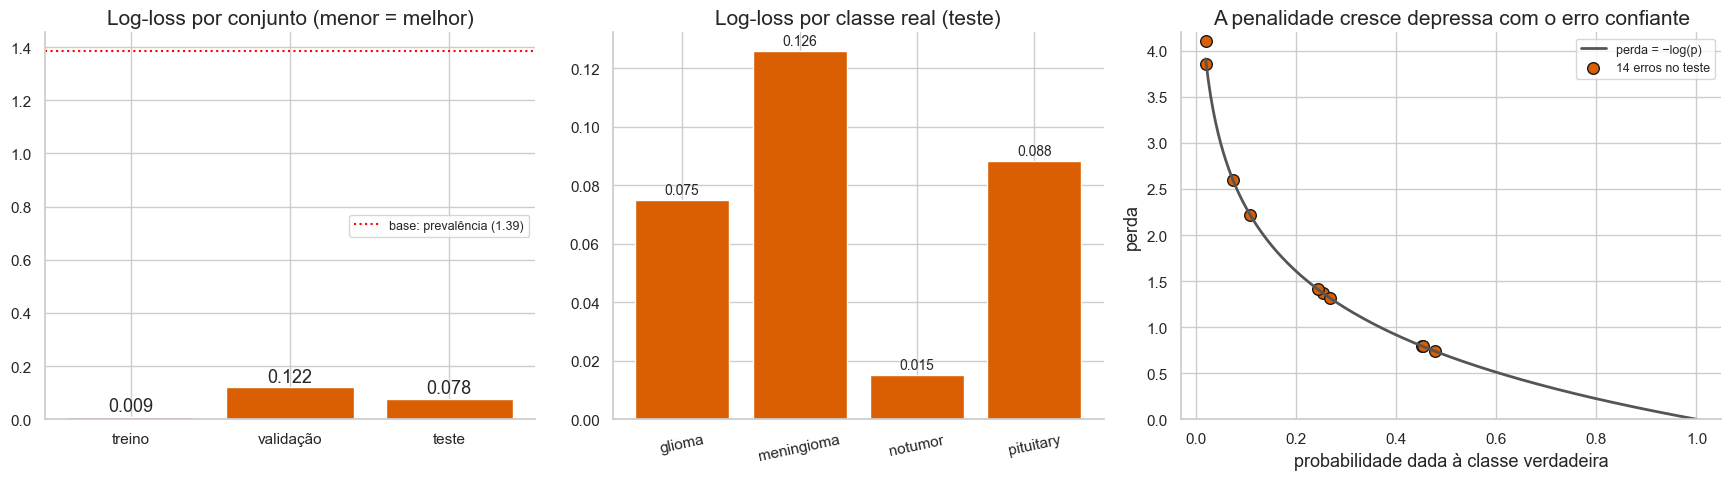

salvo: 10_log_loss.png


In [13]:
prev = np.bincount(Y["train"]) / len(Y["train"]); ll_prev = log_loss(Y["test"], np.tile(prev, (len(Y["test"]), 1)), labels=list(range(NC)))
LL = {NOME_S[s]: log_loss(Y[s], PROB[s], labels=list(range(NC))) for s in SPL3}; l = perda(Y["test"], PROB["test"]); k5 = max(1, int(.05 * len(l))); conc = 100 * np.sort(l)[::-1][:k5].sum() / l.sum()
fig, ax = plt.subplots(1, 3, figsize=(17.5, 5), gridspec_kw={"width_ratios": [1, 1, 1.1]})
ax[0].bar(list(LL), list(LL.values()), color=COR); ax[0].axhline(ll_prev, color="red", ls=":", label=f"base: prevalência ({ll_prev:.2f})"); ax[0].set_title("Log-loss por conjunto (menor = melhor)"); ax[0].legend(fontsize=9)
for i, v in enumerate(LL.values()): ax[0].text(i, v + .02, f"{v:.3f}", ha="center")
llc = [l[Y["test"] == i].mean() for i in range(NC)]; ax[1].bar(CLASSES, llc, color=COR); ax[1].set_title("Log-loss por classe real (teste)"); ax[1].tick_params(axis="x", labelrotation=12)
for i, v in enumerate(llc): ax[1].text(i, v + .002, f"{v:.3f}", ha="center", fontsize=10)
pg = np.linspace(.02, 1, 200); ax[2].plot(pg, -np.log(pg), color="#555", lw=2, label="perda = −log(p)"); pt_ = PROB["test"][np.arange(len(Y["test"])), Y["test"]]; err = pt_[PRED["test"] != Y["test"]]
ax[2].scatter(np.clip(err, .02, 1), -np.log(np.clip(err, 1e-12, 1)), color=COR, s=70, edgecolor="k", label=f"{len(err)} erros no teste"); ax[2].set_ylim(0, 4.2); ax[2].set_xlabel("probabilidade dada à classe verdadeira"); ax[2].set_ylabel("perda"); ax[2].set_title("A penalidade cresce depressa com o erro confiante"); ax[2].legend(fontsize=9)
plt.tight_layout(); reg_tab("08_logloss", pd.DataFrame({"Log-loss": LL}), "Log-loss por conjunto")
NUM.update(logloss_teste=round(LL["teste"], 4), logloss_val=round(LL["validação"], 4), logloss_treino=round(LL["treino"], 4), logloss_prevalencia=round(ll_prev, 4), concentracao_logloss_top5pct=round(conc, 1), brier_teste=round(MET.loc["Brier", "teste"], 4))
salvar("10_log_loss.png", "Log-loss: a confiança do modelo é boa, não só o acerto?",
       "Log-loss em treino, validação e teste contra a base de prever sempre a prevalência, o log-loss por classe e a curva −log(p) com os erros reais do teste sobre ela.",
       "Menor é melhor, e o valor deve ficar muito abaixo da base. Os pontos mais altos da curva são erros cometidos com alta confiança, que concentram o log-loss.",
       f"Log-loss: treino {LL['treino']:.3f}, validação {LL['validação']:.3f} e teste {LL['teste']:.3f}, contra {ll_prev:.2f} da base da prevalência. Os 5% de imagens de maior perda respondem por {conc:.0f}% do log-loss do teste: poucos erros confiantes dominam o valor. Brier no teste: {NUM['brier_teste']:.4f}.")

## 7. Calibração e predição seletiva
Um bom classificador médico precisa **saber quando não sabe**. O **diagrama de confiabilidade** compara a confiança declarada com a acurácia observada (faixas com o mesmo nº de imagens); o **ECE** resume o desvio. Na **predição seletiva**, o sistema responde só às imagens mais confiantes e encaminha as demais para revisão humana.

,Limiar de confiança,Cobertura,Acurácia nas respondidas,Encaminhadas p/ revisão,Erros que escapam
0,0.50,0.9956,0.9808,3,13
1,0.70,0.9897,0.9852,7,10
2,0.80,0.9736,0.9894,18,7
3,0.90,0.9515,0.9938,33,4
4,0.95,0.9236,0.9936,52,4
5,0.99,0.8385,1.0000,110,0


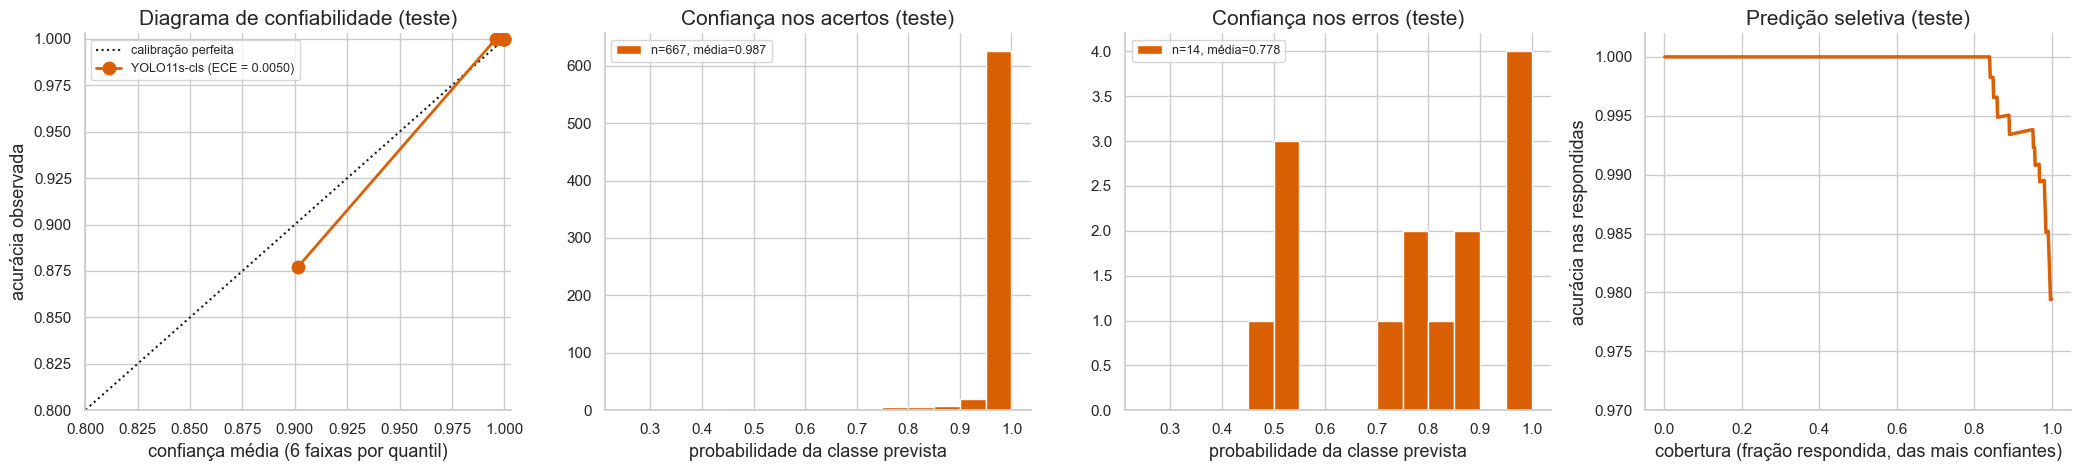

salvo: 11_calibracao.png


In [14]:
P = PROB["test"]; conf, ok = P.max(1), PRED["test"] == Y["test"]; grupos = np.array_split(np.argsort(conf), 6)
xs, ys, ns = [conf[g_].mean() for g_ in grupos], [ok[g_].mean() for g_ in grupos], [len(g_) for g_ in grupos]; E = ece(Y["test"], P)
fig, ax = plt.subplots(1, 4, figsize=(21, 4.9)); ax[0].plot([0, 1], [0, 1], "k:", label="calibração perfeita"); ax[0].plot(xs, ys, "o-", color=COR, lw=2, ms=9, label=f"{ALVO} (ECE = {E:.4f})")
ax[0].set_xlim(.8, 1.003); ax[0].set_ylim(.8, 1.003); ax[0].set_xlabel("confiança média (6 faixas por quantil)"); ax[0].set_ylabel("acurácia observada"); ax[0].set_title("Diagrama de confiabilidade (teste)"); ax[0].legend(fontsize=9, loc="upper left")
for a, tipo, v in ((ax[1], "acertos", conf[ok]), (ax[2], "erros", conf[~ok])):
    if len(v): a.hist(v, bins=np.linspace(.25, 1, 16), color=COR, label=f"n={len(v)}, média={v.mean():.3f}"); a.legend(fontsize=9)
    a.set_title(f"Confiança nos {tipo} (teste)"); a.set_xlabel("probabilidade da classe prevista")
o = np.argsort(-conf); cov = np.arange(1, len(o) + 1) / len(o); accs_ = np.cumsum(ok[o]) / np.arange(1, len(o) + 1)
ax[3].plot(cov, accs_, color=COR, lw=2.5); ax[3].set_ylim(.97, 1.002); ax[3].set_xlabel("cobertura (fração respondida, das mais confiantes)"); ax[3].set_ylabel("acurácia nas respondidas"); ax[3].set_title("Predição seletiva (teste)"); plt.tight_layout()
linhas = [{"Limiar de confiança": t, "Cobertura": float((conf >= t).mean()), "Acurácia nas respondidas": float(ok[conf >= t].mean()) if (conf >= t).any() else np.nan, "Encaminhadas p/ revisão": int((conf < t).sum()), "Erros que escapam": int((~ok & (conf >= t)).sum())} for t in (.5, .7, .8, .9, .95, .99)]
reg_tab("09_predicao_seletiva", pd.DataFrame(linhas), "Predição seletiva por limiar de confiança", index=False)
def cob_para(alvo): k = np.where(accs_ >= alvo)[0]; return (k.max() + 1) / len(o) if len(k) else 0
NUM.update(ece_teste=round(E, 4), conf_media_acertos=round(float(conf[ok].mean()), 4), conf_media_erros=round(float(conf[~ok].mean()), 4) if (~ok).any() else None, cobertura_acc995=round(cob_para(.995), 3), faixa1_prometeu=round(xs[0], 3), faixa1_aconteceu=round(ys[0], 3))
salvar("11_calibracao.png", "Calibração e predição seletiva",
       "Esquerda: confiança declarada × acurácia observada em 6 faixas com o mesmo número de imagens. Centro: distribuição da confiança nos acertos e nos erros. Direita: acurácia obtida ao responder só às imagens mais confiantes, em função da cobertura.",
       "Pontos sobre a diagonal = confiança honesta; abaixo = excesso de confiança. Erros com confiança menor que os acertos mostram que o modelo 'sabe quando duvida'. A curva alta à esquerda mostra que as previsões mais confiantes são mais confiáveis.",
       f"ECE no teste {E:.4f} (meta ≤ {CRIT['ece_max']}); confiança média {conf[ok].mean():.3f} nos acertos e {(conf[~ok].mean() if (~ok).any() else float('nan')):.3f} nos erros. Faixa menos confiante: prometeu {xs[0]:.3f}, aconteceu {ys[0]:.3f}. A maior cobertura que mantém ≥ 99,5% de acurácia nas respondidas é {100*cob_para(.995):.0f}%; o restante iria para revisão humana.")

## 8. Visão clínica: tumor × sem tumor
Nem todo erro pesa igual: o pior é o **falso negativo** (tumor classificado como `notumor`). Agrupamos glioma, meningioma e pituitary em *tumor* e usamos o score P(tumor) = 1 − P(notumor). Mostramos sensibilidade e especificidade em cada limiar, o ponto de operação padrão (0,50) e o limiar escolhido **na validação** para sensibilidade ≥ 99,5%, medido no teste.

,Corte,Conjunto,Sensibilidade,Especificidade,Falsos negativos,Falsos positivos
0,"corte 0,50",validação,0.9923,0.9910,8,3
1,"corte 0,50",teste,0.9924,0.9872,4,2
2,corte da validação (0.07),validação,0.9952,0.9642,5,12
3,corte da validação (0.07),teste,0.9981,0.9808,1,3


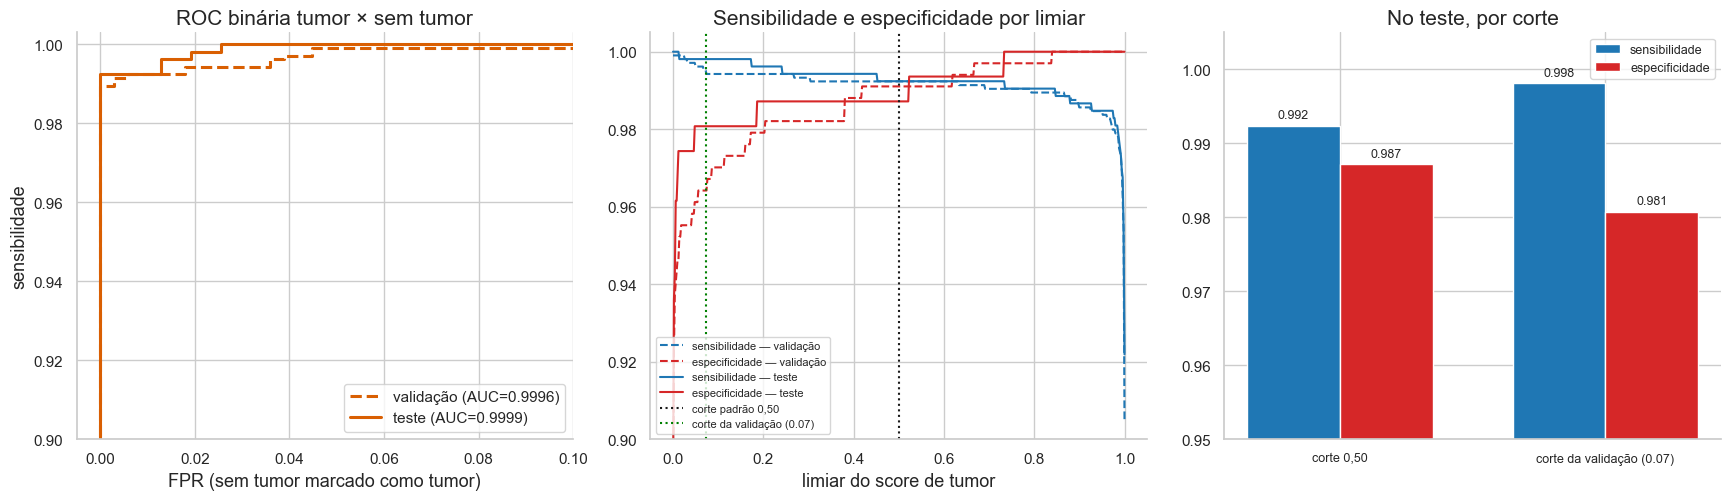

salvo: 12_visao_clinica.png


In [15]:
yb = {s: (Y[s] != i_nt).astype(int) for s in SV}; sc = {s: 1 - PROB[s][:, i_nt] for s in SV}; gr = np.linspace(.0005, .9995, 500)
def sens_esp(s, t): pr = sc[s] >= t; tp = ((yb[s] == 1) & pr).sum(); fn = ((yb[s] == 1) & ~pr).sum(); tn = ((yb[s] == 0) & ~pr).sum(); fp = ((yb[s] == 0) & pr).sum(); return tp / (tp + fn), tn / (tn + fp), int(fn), int(fp)
sv = np.array([sens_esp("val", t)[0] for t in gr]); ok_ = np.where(sv >= .995)[0]; t_sel = float(gr[ok_.max()]) if len(ok_) else .5
fig, ax = plt.subplots(1, 3, figsize=(17.5, 5.2))
for s, ls in (("val", "--"), ("test", "-")):
    f, t, _ = roc_curve(yb[s], sc[s]); ax[0].plot(f, t, ls, color=COR, lw=2.2, label=f"{NOME_S[s]} (AUC={roc_auc_score(yb[s], sc[s]):.4f})")
ax[0].set_xlim(-.005, .1); ax[0].set_ylim(.9, 1.003); ax[0].set_xlabel("FPR (sem tumor marcado como tumor)"); ax[0].set_ylabel("sensibilidade"); ax[0].set_title("ROC binária tumor × sem tumor"); ax[0].legend(loc="lower right")
for s, ls in (("val", "--"), ("test", "-")):
    ax[1].plot(gr, [sens_esp(s, t)[0] for t in gr], ls, color="#1f77b4", label=f"sensibilidade — {NOME_S[s]}"); ax[1].plot(gr, [sens_esp(s, t)[1] for t in gr], ls, color="#d62728", label=f"especificidade — {NOME_S[s]}")
ax[1].axvline(.5, color="k", ls=":", label="corte padrão 0,50"); ax[1].axvline(t_sel, color="green", ls=":", label=f"corte da validação ({t_sel:.2f})"); ax[1].set_ylim(.9, 1.005); ax[1].set_xlabel("limiar do score de tumor"); ax[1].set_title("Sensibilidade e especificidade por limiar"); ax[1].legend(fontsize=8, loc="lower left")
op = {"corte 0,50": .5, f"corte da validação ({t_sel:.2f})": t_sel}; linhas = []
for nome, t in op.items():
    for s in SV: se, es, fn, fp = sens_esp(s, t); linhas.append({"Corte": nome, "Conjunto": NOME_S[s], "Sensibilidade": se, "Especificidade": es, "Falsos negativos": fn, "Falsos positivos": fp})
OP = pd.DataFrame(linhas); sub = OP[OP["Conjunto"] == "teste"]; x = np.arange(2); w = .35
ax[2].bar(x - w / 2, sub["Sensibilidade"], w, color="#1f77b4", label="sensibilidade"); ax[2].bar(x + w / 2, sub["Especificidade"], w, color="#d62728", label="especificidade"); ax[2].set_xticks(x); ax[2].set_xticklabels(sub["Corte"], fontsize=9); ax[2].set_ylim(.95, 1.005); ax[2].set_title("No teste, por corte"); ax[2].legend(fontsize=9)
for i, (a_, b_) in enumerate(zip(sub["Sensibilidade"], sub["Especificidade"])): ax[2].text(i - w / 2, a_ + .001, f"{a_:.3f}", ha="center", fontsize=9); ax[2].text(i + w / 2, b_ + .001, f"{b_:.3f}", ha="center", fontsize=9)
plt.tight_layout(); reg_tab("10_visao_clinica", OP, "Sensibilidade e especificidade por corte", index=False)
d50 = sens_esp("test", .5); dsel = sens_esp("test", t_sel); auc_b = roc_auc_score(yb["test"], sc["test"])
NUM.update(auc_binaria_teste=round(auc_b, 4), sens_teste_corte050=round(d50[0], 4), esp_teste_corte050=round(d50[1], 4), fn_teste_corte050=d50[2], fp_teste_corte050=d50[3], limiar_sens995_validacao=round(t_sel, 3), sens_teste_corte_val=round(dsel[0], 4), esp_teste_corte_val=round(dsel[1], 4), fn_teste_corte_val=dsel[2], fp_teste_corte_val=dsel[3])
salvar("12_visao_clinica.png", "Visão clínica: quantos tumores passam despercebidos?",
       "As três classes de tumor agrupadas contra 'notumor': ROC binária, sensibilidade e especificidade em cada limiar do score de tumor e os resultados no teste com o corte padrão 0,50 e com o corte escolhido na validação para sensibilidade ≥ 99,5%.",
       "O erro mais grave é o falso negativo (tumor passando como normal). Subir o limiar troca sensibilidade por especificidade; o corte deve ser escolhido na validação e medido uma vez no teste.",
       f"AUC binária no teste {auc_b:.4f}. Com o corte 0,50: sensibilidade {d50[0]:.3f} ({pl(d50[2], 'falso negativo', 'falsos negativos')}) e especificidade {d50[1]:.3f} ({pl(d50[3], 'falso positivo', 'falsos positivos')}). Com o corte da validação ({t_sel:.2f}): sensibilidade {dsel[0]:.3f} ({pl(dsel[2], 'falso negativo', 'falsos negativos')}) e especificidade {dsel[1]:.3f} ({pl(dsel[3], 'falso positivo', 'falsos positivos')}).")

## 9. Incerteza estatística
Com ~700 imagens de teste, 1–2 erros mudam a 2ª casa decimal. O **bootstrap** (2000 reamostragens) dá intervalos de 95% para acurácia, F1 e log-loss. A **estabilidade por dobras** divide o teste em 5 dobras estratificadas, repetido 10 vezes (50 dobras): a média ± desvio mostra a oscilação da *amostra de teste* (não a do treino, pois não retreinamos).

,Métrica,Média,IC 95% inf,IC 95% sup
0,Acurácia,0.9795,0.9692,0.9897
1,F1 macro,0.9795,0.9682,0.9898
2,Log-loss,0.0775,0.0409,0.1219


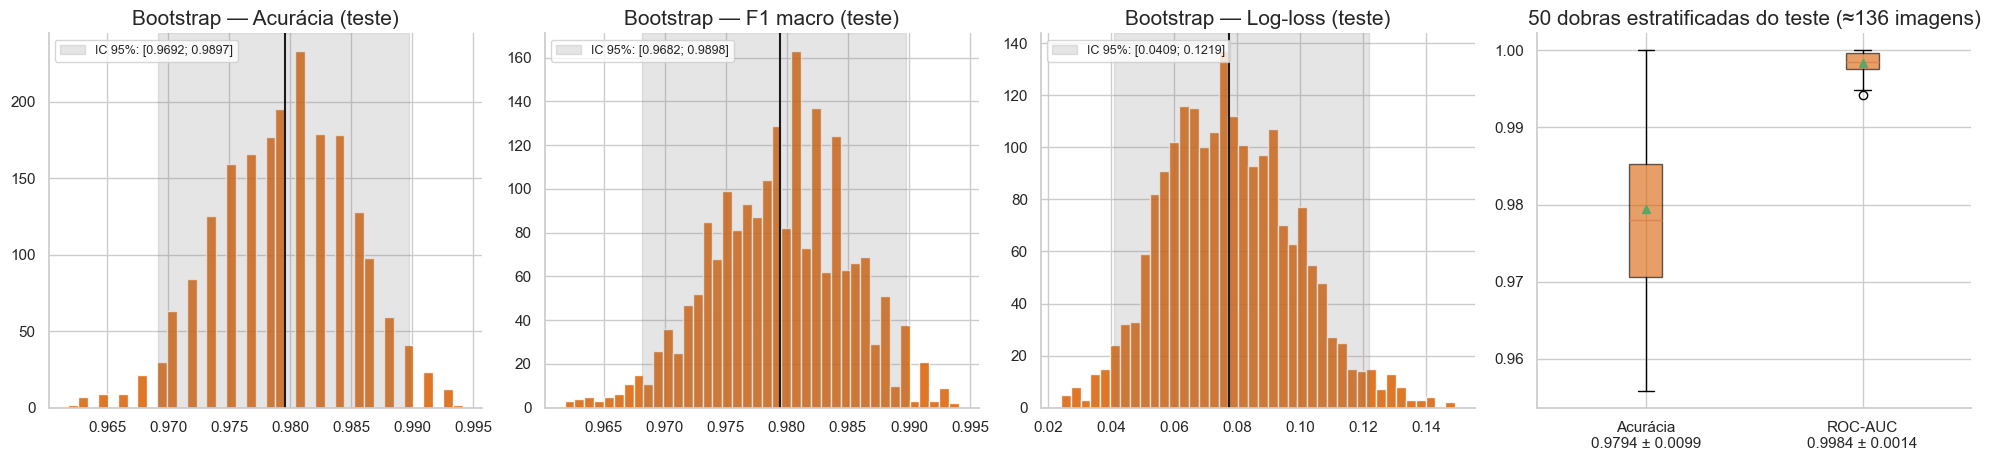

salvo: 13_incerteza.png


In [16]:
rng = np.random.default_rng(SEED); N = len(Y["test"]); ba, bf, bl = [], [], []
for _ in range(N_BOOT):
    i = rng.integers(0, N, N); ba.append((PRED["test"][i] == Y["test"][i]).mean()); bf.append(f1_score(Y["test"][i], PRED["test"][i], average="macro")); bl.append(perda(Y["test"][i], PROB["test"][i]).mean())
ba, bf, bl = map(np.array, (ba, bf, bl)); ic = lambda v: np.percentile(v, [2.5, 97.5])
rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=SEED); fa, fu, ff = [], [], []
for _, idx in rskf.split(np.zeros(N), Y["test"]):
    yy, Pp = Y["test"][idx], PROB["test"][idx]; pr = Pp.argmax(1); fa.append((pr == yy).mean()); ff.append(f1_score(yy, pr, average="macro")); fu.append(roc_auc_score(yy, Pp, multi_class="ovr"))
fa, fu, ff = map(np.array, (fa, fu, ff))
fig, ax = plt.subplots(1, 4, figsize=(20, 4.8))
for a, v, tit in ((ax[0], ba, "Acurácia"), (ax[1], bf, "F1 macro"), (ax[2], bl, "Log-loss")):
    a.hist(v, bins=40, color=COR, alpha=.85); lo, hi = ic(v); a.axvspan(lo, hi, color="gray", alpha=.2, label=f"IC 95%: [{lo:.4f}; {hi:.4f}]"); a.axvline(v.mean(), color="k", lw=1.5); a.set_title(f"Bootstrap — {tit} (teste)"); a.legend(fontsize=9, loc="upper left")
bp = ax[3].boxplot([fa, fu], labels=[f"Acurácia\n{fa.mean():.4f} ± {fa.std(ddof=1):.4f}", f"ROC-AUC\n{fu.mean():.4f} ± {fu.std(ddof=1):.4f}"], patch_artist=True, showmeans=True)
for p_ in bp["boxes"]: p_.set_facecolor(COR); p_.set_alpha(.6)
ax[3].set_title(f"50 dobras estratificadas do teste (≈{int(N/5)} imagens)"); plt.tight_layout()
ICT = pd.DataFrame([{"Métrica": m, "Média": v.mean(), "IC 95% inf": ic(v)[0], "IC 95% sup": ic(v)[1]} for m, v in (("Acurácia", ba), ("F1 macro", bf), ("Log-loss", bl))]); reg_tab("11_bootstrap", ICT, "Intervalos de confiança (bootstrap, teste)", index=False)
lo, hi = wilson(int((PRED["test"] == Y["test"]).sum()), N)
NUM.update(ic_acc_inf=round(ic(ba)[0], 4), ic_acc_sup=round(ic(ba)[1], 4), ic_f1_inf=round(ic(bf)[0], 4), ic_f1_sup=round(ic(bf)[1], 4), ic_ll_inf=round(ic(bl)[0], 4), ic_ll_sup=round(ic(bl)[1], 4), wilson_acc_inf=round(lo, 4), wilson_acc_sup=round(hi, 4),
           dobras_acc_media=round(fa.mean(), 4), dobras_acc_desvio=round(fa.std(ddof=1), 4), dobras_auc_media=round(fu.mean(), 4), dobras_auc_desvio=round(fu.std(ddof=1), 4), dobras_f1_media=round(ff.mean(), 4), dobras_acc_min=round(fa.min(), 4), dobras_acc_max=round(fa.max(), 4))
salvar("13_incerteza.png", "Incerteza estatística: intervalos de confiança e estabilidade por dobras",
       "Distribuições bootstrap da acurácia, do F1 macro e do log-loss no teste com seus intervalos de 95%, e a distribuição da acurácia e da ROC-AUC em 50 dobras estratificadas do teste.",
       "Intervalos largos indicam que o número depende de poucas imagens. A média ± desvio por dobras é o resultado honesto de uma validação (nunca um número solto). Mede a oscilação da amostra de teste, não a variância entre treinos.",
       f"Acurácia no teste {acc('test'):.4f} (IC 95% bootstrap [{ic(ba)[0]:.4f}; {ic(ba)[1]:.4f}]; Wilson [{lo:.4f}; {hi:.4f}]); F1 macro IC [{ic(bf)[0]:.4f}; {ic(bf)[1]:.4f}]; log-loss IC [{ic(bl)[0]:.3f}; {ic(bl)[1]:.3f}]. Em 50 dobras de ≈{int(N/5)} imagens: acurácia {fa.mean():.4f} ± {fa.std(ddof=1):.4f} (mín. {fa.min():.3f}, máx. {fa.max():.3f}) e ROC-AUC {fu.mean():.4f} ± {fu.std(ddof=1):.4f}.")

## 10. Robustez a perturbações
Imagens reais de RM variam (ruído, desfoque, brilho, compressão, posicionamento). Aplicamos perturbações controladas a uma amostra **estratificada** do teste (sempre a mesma, com a mesma semente) e medimos a queda de acurácia. São perturbações sintéticas: indicam sensibilidade, não substituem validação em dados de outro hospital ou scanner.

  original                   acc=0.975 (10s)


  ruído gaussiano σ=10       acc=0.767 (20s)


  ruído gaussiano σ=25       acc=0.400 (29s)


  desfoque (raio 2)          acc=0.667 (37s)


  desfoque (raio 4)          acc=0.250 (45s)


  brilho −30%                acc=0.983 (53s)


... (3 outputs left out)

  rotação 10°                acc=0.917 (87s)


  flip horizontal            acc=0.975 (94s)


  oclusão 25% da largura     acc=0.983 (102s)


,Acurácia,Log-loss
original,0.9750,0.1138
ruído gaussiano σ=10,0.7667,0.9188
ruído gaussiano σ=25,0.4000,3.6748
desfoque (raio 2),0.6667,1.2711
desfoque (raio 4),0.2500,8.2588
brilho −30%,0.9833,0.0887
brilho +30%,0.9667,0.1279
contraste −40%,0.9833,0.0876
JPEG q=20,0.5833,1.5021
rotação 10°,0.9167,0.2681


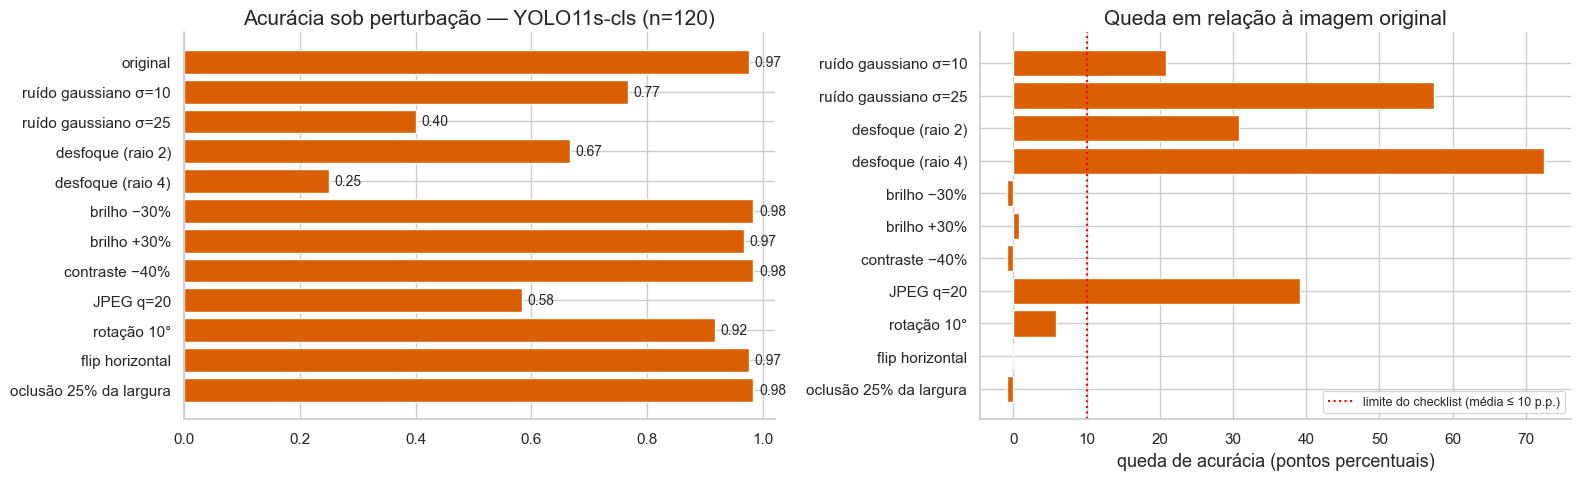

salvo: 14_robustez.png


In [17]:
def p_ruido(sig):
    def f(im, r): a = np.asarray(im, dtype=np.float32) + r.normal(0, sig, (im.size[1], im.size[0], 3)); return Image.fromarray(np.clip(a, 0, 255).astype(np.uint8))
    return f
def p_jpeg(q):
    def f(im, r): b = io.BytesIO(); im.save(b, "JPEG", quality=q); b.seek(0); return Image.open(b).convert("RGB")
    return f
def p_oclusao(frac):
    def f(im, r):
        w, h = im.size; s_ = int(w * frac); x0, y0 = int(r.integers(0, w - s_)), int(r.integers(0, h - s_)); o = im.copy(); o.paste((0, 0, 0), (x0, y0, x0 + s_, y0 + s_)); return o
    return f
PERT = {"original": lambda im, r: im, "ruído gaussiano σ=10": p_ruido(10), "ruído gaussiano σ=25": p_ruido(25), "desfoque (raio 2)": lambda im, r: im.filter(ImageFilter.GaussianBlur(2)), "desfoque (raio 4)": lambda im, r: im.filter(ImageFilter.GaussianBlur(4)),
        "brilho −30%": lambda im, r: ImageEnhance.Brightness(im).enhance(.7), "brilho +30%": lambda im, r: ImageEnhance.Brightness(im).enhance(1.3), "contraste −40%": lambda im, r: ImageEnhance.Contrast(im).enhance(.6), "JPEG q=20": p_jpeg(20),
        "rotação 10°": lambda im, r: im.rotate(10, fillcolor=(0, 0, 0)), "flip horizontal": lambda im, r: im.transpose(Image.FLIP_LEFT_RIGHT), "oclusão 25% da largura": p_oclusao(.25)}
rng_r = np.random.default_rng(SEED); idx_rob = []
for i in range(NC): pool = np.where(Y["test"] == i)[0]; idx_rob += list(rng_r.choice(pool, min(len(pool), N_ROBUSTEZ // NC), replace=False))
idx_rob = np.array(sorted(idx_rob)); y_rob = Y["test"][idx_rob]; imgs0 = [Image.open(CAM["test"][i]).convert("RGB") for i in idx_rob]
t0 = time.time(); ROB = {}
for nome, f in PERT.items():
    r = np.random.default_rng(SEED); p = prob_pil([f(im, r) for im in imgs0]); ROB[nome] = (accuracy_score(y_rob, p.argmax(1)), log_loss(y_rob, p, labels=list(range(NC)))); print(f"  {nome:26s} acc={ROB[nome][0]:.3f} ({time.time()-t0:.0f}s)")
RB = pd.DataFrame(ROB, index=["Acurácia", "Log-loss"]).T; queda = {n: ROB["original"][0] - ROB[n][0] for n in ROB if n != "original"}; qm = float(np.mean(list(queda.values())))
fig, ax = plt.subplots(1, 2, figsize=(16, 5)); ax[0].barh(list(ROB), [v[0] for v in ROB.values()], color=COR); ax[0].set_xlim(0, 1.02); ax[0].invert_yaxis(); ax[0].set_title(f"Acurácia sob perturbação — {ALVO} (n={len(y_rob)})")
for i, v in enumerate(ROB.values()): ax[0].text(v[0] + .01, i, f"{v[0]:.2f}", va="center", fontsize=10)
ax[1].barh(list(queda), [100 * v for v in queda.values()], color=COR); ax[1].axvline(100 * CRIT["queda_robustez_max"], color="red", ls=":", label=f"limite do checklist (média ≤ {100*CRIT['queda_robustez_max']:.0f} p.p.)"); ax[1].invert_yaxis(); ax[1].set_xlabel("queda de acurácia (pontos percentuais)"); ax[1].set_title("Queda em relação à imagem original"); ax[1].legend(fontsize=9, loc="lower right")
plt.tight_layout(); reg_tab("12_robustez", RB, "Acurácia e log-loss sob perturbação")
pior = max(queda, key=queda.get); fracas = [n for n, v in queda.items() if v > .10]; leves = [n for n, v in queda.items() if v <= .02]
NUM.update(acc_original_amostra=round(ROB["original"][0], 4), queda_media_robustez_pp=round(100 * qm, 1), pior_perturbacao=pior, queda_pior_pp=round(100 * queda[pior], 1), n_perturbacoes_queda_gt10=len(fracas), n_robustez=int(len(y_rob)))
salvar("14_robustez.png", "Robustez a perturbações sintéticas",
       "Acurácia do modelo quando imagens de teste recebem ruído gaussiano, desfoque, mudança de brilho e contraste, compressão JPEG, rotação, espelhamento ou oclusão, e a queda em relação à imagem original. Perturbações sintéticas indicam sensibilidade, não substituem validação em outro scanner ou hospital.",
       "Barras longas na esquerda = mantém a acurácia; barras longas na direita = grande queda. Quanto menor a queda média, mais robusto.",
       f"Queda média de {100*qm:.1f} p.p. (acurácia original na amostra: {ROB['original'][0]:.3f}). Pior caso: {pior} (−{100*queda[pior]:.0f} p.p.). Perturbações com queda > 10 p.p.: {', '.join(fracas) if fracas else 'nenhuma'}. Praticamente sem efeito (≤ 2 p.p.): {', '.join(leves) if leves else 'nenhuma'}.")

## 11. Interpretabilidade: Grad-CAM
Mapas de ativação por gradiente mostram as regiões que mais influenciaram a decisão (vermelho/amarelo = mais importante). Esperamos foco na região da lesão ou na anatomia relevante, e não em bordas, fundo ou artefatos. Primeiro, um acerto de cada classe (as mesmas imagens para qualquer modelo); depois, as imagens que **este modelo errou**, das mais confiantes para as menos. É leitura qualitativa: não prova causalidade.

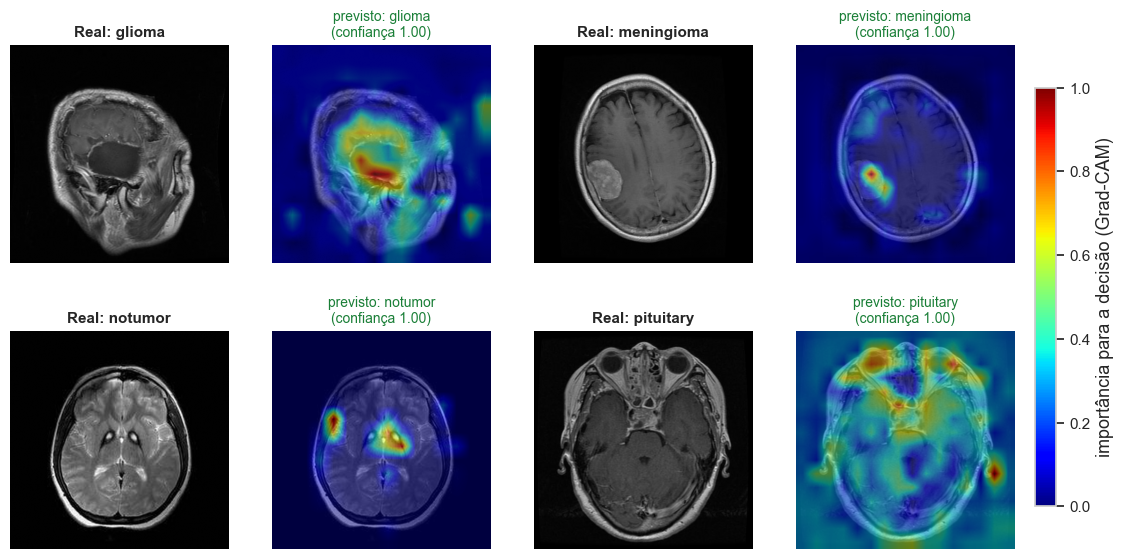

salvo: 15_gradcam_acertos.png


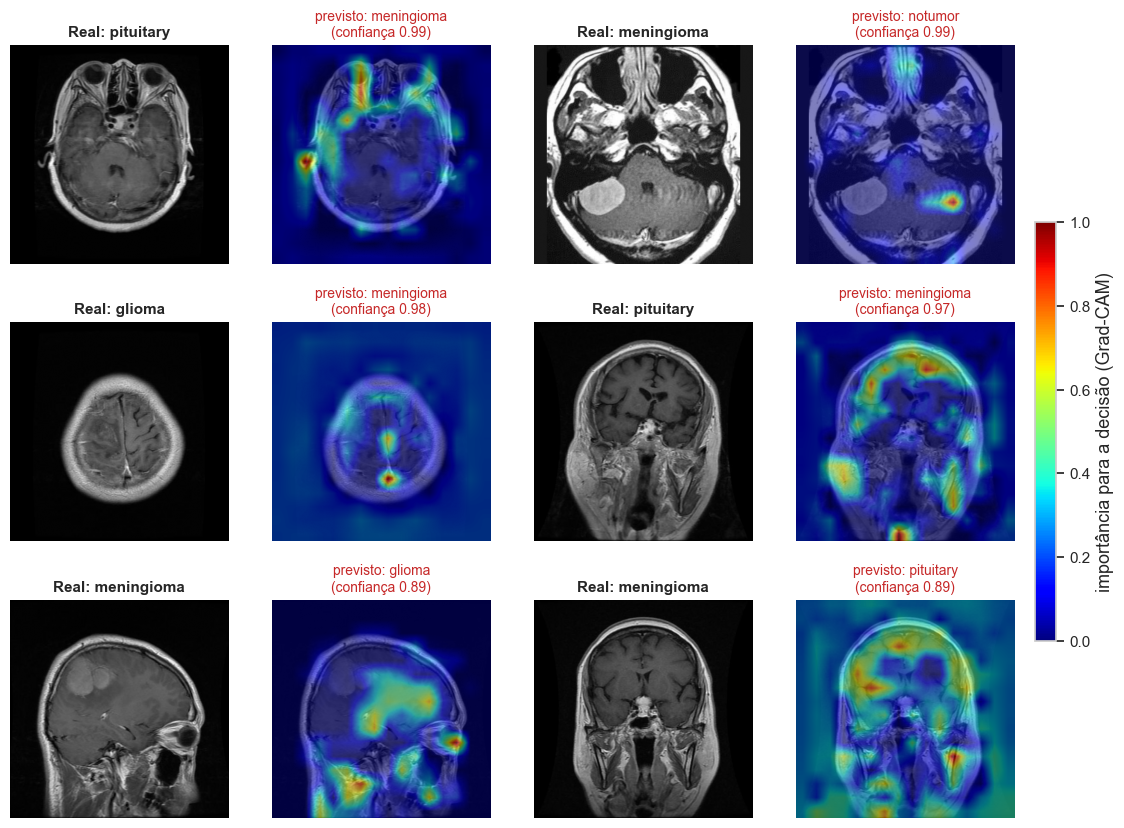

salvo: 16_gradcam_erros.png


In [18]:
def gradcam(net, camada, x, classe=None):
    ativ, grads = [], []
    def fh(mod, inp, out): ativ.append(out); out.register_hook(lambda g: grads.append(g))
    h = camada.register_forward_hook(fh)
    with torch.enable_grad():
        xx = x.clone().requires_grad_(True); net.zero_grad(); out = net(xx); out = out[0] if isinstance(out, (tuple, list)) else out
        c = int(out.argmax(1)) if classe is None else classe; out[0, c].backward()
    h.remove(); a, g_ = ativ[0].detach(), grads[0].detach(); cm = TF.relu((g_.mean((2, 3), keepdim=True) * a).sum(1, keepdim=True))
    cm = TF.interpolate(cm, size=(IMG_SIZE, IMG_SIZE), mode="bilinear", align_corners=False)[0, 0]; cm = cm / (cm.max() + 1e-8); return cm.cpu().numpy(), c
if EH_YOLO: camada, tf_gc = rede.model[-2], (lambda im: transforms.ToTensor()(im.resize((IMG_SIZE, IMG_SIZE))).unsqueeze(0).to(device))
else: camada, tf_gc = rede.features[-1], (lambda im: tf_aval(im).unsqueeze(0).to(device))

def painel(idxs, nome, titulo, mostra, ler, resultado):
    n = len(idxs); linhas = int(np.ceil(n / 2)); fig, ax = plt.subplots(linhas, 4, figsize=(13.5, 3.4 * linhas)); ax = np.atleast_2d(ax).reshape(linhas, 4)
    for a in ax.ravel(): a.axis("off")
    for k, i in enumerate(idxs):
        r_, c0 = k // 2, (k % 2) * 2; im = Image.open(CAM["test"][i]).convert("RGB"); real = CLASSES[Y["test"][i]]; base = im.convert("L"); mapa, c = gradcam(rede, camada, tf_gc(im))
        ax[r_, c0].imshow(base, cmap="gray"); ax[r_, c0].set_title(f"Real: {real}", fontsize=11, fontweight="bold")
        ax[r_, c0 + 1].imshow(base, cmap="gray"); ax[r_, c0 + 1].imshow(mapa, cmap="jet", alpha=.5, vmin=0, vmax=1)
        ax[r_, c0 + 1].set_title(f"previsto: {CLASSES[c]}\n(confiança {PROB['test'][i].max():.2f})", fontsize=10, color="#1a7f37" if CLASSES[c] == real else "#c62828")
    sm = plt.cm.ScalarMappable(cmap="jet", norm=plt.Normalize(0, 1)); cb = fig.colorbar(sm, ax=ax, fraction=.02, pad=.02); cb.set_label("importância para a decisão (Grad-CAM)")
    salvar(nome, titulo, mostra, ler, resultado)

# acertos: um por classe, entre imagens que os DOIS modelos acertam (as mesmas imagens usadas em outros relatórios)
PRED_Y = np.load(CACHE / f"yolo_test_{int(PESO_YOLO.stat().st_mtime)}_{len(DS['test'])}.npy").argmax(1) if (CACHE / f"yolo_test_{int(PESO_YOLO.stat().st_mtime)}_{len(DS['test'])}.npy").exists() else PRED["test"]
PRED_C = np.load(CACHE / f"cnn_test_{int(PESO_CNN.stat().st_mtime)}_{len(DS['test'])}.npy").argmax(1) if (CACHE / f"cnn_test_{int(PESO_CNN.stat().st_mtime)}_{len(DS['test'])}.npy").exists() else PRED["test"]
rngg = np.random.default_rng(SEED); corretos = []
for c in range(NC):
    pool = np.where((Y["test"] == c) & (PRED_Y == c) & (PRED_C == c))[0]; pool = pool if len(pool) else np.where((Y["test"] == c) & (PRED["test"] == c))[0]; corretos.append(int(rngg.choice(pool)))
errs = np.where(PRED["test"] != Y["test"])[0]; errs = errs[np.argsort(-PROB["test"][errs].max(1))]; sel_err = list(errs[:N_GRADCAM_ERROS])
try:
    painel(corretos, "15_gradcam_acertos.png", f"Mapas de calor (Grad-CAM) de {ALVO}: um acerto por classe",
           "Imagem de RM original e o mapa de calor do que mais influenciou a decisão do modelo, para um exemplo correto de cada classe (glioma, meningioma, notumor, pituitary). Vermelho/amarelo = região mais importante.",
           "Esperamos calor sobre a lesão ou a anatomia relevante (por exemplo, a região da hipófise no caso pituitary), e não sobre bordas, fundo escuro ou artefatos. Em 'notumor' não há lesão: calor difuso é esperado. Leitura qualitativa, sem causalidade.",
           "Nos exemplos mostrados o modelo acerta as 4 imagens com confiança máxima. Em glioma e meningioma o calor se concentra sobre a lesão (no meningioma, num ponto menor que a massa), mas há pontos secundários soltos no fundo e na borda do crânio. Em notumor aparecem dois focos, um deles na borda lateral do crânio, fora de uma região de interesse. Em pituitary o calor é disperso, com pontos nas órbitas e na borda lateral (orelha) e pouca ênfase na região da sela. A atenção é mais fragmentada e menos específica da lesão. Interpretação feita pela inspeção visual destes exemplos.")
except Exception as e: print("Grad-CAM (acertos) falhou:", type(e).__name__, str(e)[:300])
try:
    if len(sel_err):
        painel(sel_err, "16_gradcam_erros.png", f"Mapas de calor (Grad-CAM) de {ALVO}: imagens que o modelo errou",
               f"As {len(sel_err)} imagens de teste que o modelo errou com maior confiança, com o mapa de calor e a classe prevista (verde = certo, vermelho = errado).",
               "Compare onde o modelo olhou quando errou: foco em região irrelevante, borda ou calor muito disperso sugere falha de atenção; foco na lesão com classe errada sugere imagem ambígua entre tipos de tumor.",
               f"O modelo errou {len(errs)} imagens no teste; o painel mostra as {len(sel_err)} de maior confiança. Na maioria dos erros mais confiantes o calor está disperso ou fora da lesão: nos dois erros de pituitary para meningioma ele cobre órbitas, bordas e regiões periféricas, sem ênfase na sela; num meningioma cerebelar visível à esquerda classificado como notumor (falso negativo com confiança 0,99) o calor está no hemisfério oposto, longe da lesão. Nos demais, pontos isolados na linha média ou regiões anteriores e inferiores. Sugere falha de atenção mais do que ambiguidade entre tipos de tumor. Interpretação feita pela inspeção visual destes exemplos.")
except Exception as e: print("Grad-CAM (erros) falhou:", type(e).__name__, str(e)[:300])

## 12. Análise de erros

,Arquivo,Real,Previsto,Confiança,Prob. da classe real,Quase-duplicata no treino?
0,Tr-pi_1255_jpg.rf.4a24eef12abfbc89962f61594be4...,pituitary,meningioma,0.9895,0.0020,não
1,Tr-me_154_jpg.rf.b8aaba76d406f4f2d0750adf76a86...,meningioma,notumor,0.9865,0.0081,não
2,Tr-gl_987_jpg.rf.be57035d7df07075c03d166f1106e...,glioma,meningioma,0.9835,0.0165,não
3,Tr-pi_452_jpg.rf.159afcb1b8e82823924ff9bc67d6d...,pituitary,meningioma,0.9676,0.0020,não
4,Tr-me_541_jpg.rf.ff3001e3f67189b5d3f16efb07b5e...,meningioma,glioma,0.8917,0.1083,não
5,Tr-me_964_jpg.rf.6d728af1f74ceef073eb6acf88f7c...,meningioma,pituitary,0.8864,0.0212,não
6,Tr-me_239_jpg.rf.8298adfe4e358f3bad6ecbff3a197...,meningioma,notumor,0.8259,0.0744,não
7,Te-gl_62_jpg.rf.e5510a0f35d1fd15d06d9a14cacfa3...,glioma,notumor,0.7588,0.0010,não
8,Tr-me_1059_jpg.rf.2c6d37e0f90724baf37c99095ad3...,meningioma,glioma,0.7556,0.2444,não
9,Te-gl_91_jpg.rf.a96f97376f7996206becc54f4d2d22...,glioma,meningioma,0.7451,0.2549,não


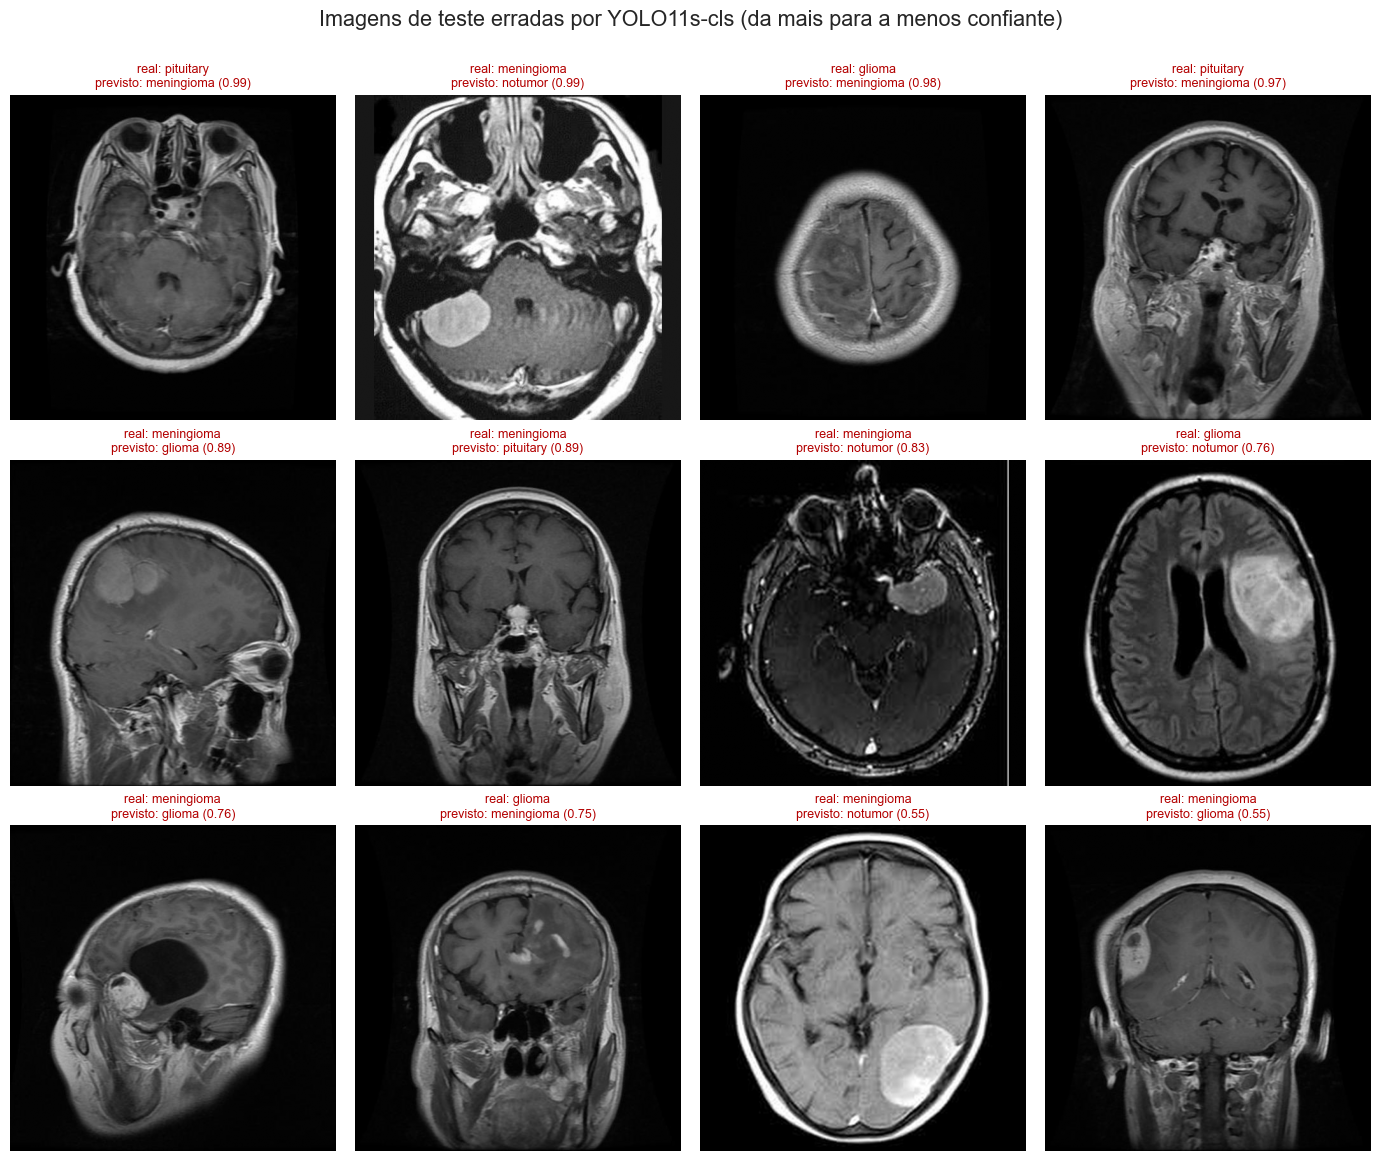

salvo: 17_galeria_erros.png


In [19]:
pe = np.where(PRED["test"] != Y["test"])[0]
ER = pd.DataFrame([{"Arquivo": Path(CAM["test"][i]).name, "Real": CLASSES[Y["test"][i]], "Previsto": CLASSES[PRED["test"][i]], "Confiança": float(PROB["test"][i].max()), "Prob. da classe real": float(PROB["test"][i][Y["test"][i]]),
                   "Quase-duplicata no treino?": "sim" if dup_tt[i] else "não"} for i in pe]).sort_values("Confiança", ascending=False).reset_index(drop=True)
reg_tab("13_erros_teste", ER, "Imagens de teste classificadas errado", index=False)
mapa = {Path(p).name: p for p in CAM["test"]}; df = ER.head(12); cols = 4; rows = int(np.ceil(max(1, len(df)) / cols)); fig, ax = plt.subplots(rows, cols, figsize=(3.5 * cols, 3.9 * rows)); ax = np.atleast_1d(ax).ravel()
for a in ax: a.axis("off")
for a, (_, r) in zip(ax, df.iterrows()): a.imshow(Image.open(mapa[r["Arquivo"]]).convert("L"), cmap="gray"); a.set_title(f"real: {r['Real']}\nprevisto: {r['Previsto']} ({r['Confiança']:.2f})", fontsize=9, color="#b30000")
fig.suptitle(f"Imagens de teste erradas por {ALVO} (da mais para a menos confiante)", y=1.0); plt.tight_layout()
conf_alta = int((ER["Confiança"] >= .9).sum()) if len(ER) else 0; cm_ = ER.groupby(["Real", "Previsto"]).size().sort_values(ascending=False) if len(ER) else pd.Series(dtype=int)
NUM.update(erros_confianca_ge90=conf_alta, erros_com_quase_duplicata=int((ER["Quase-duplicata no treino?"] == "sim").sum()) if len(ER) else 0, confianca_media_erros=round(float(ER["Confiança"].mean()), 3) if len(ER) else None)
salvar("17_galeria_erros.png", "Galeria dos erros no conjunto de teste",
       "As imagens de teste que o modelo classificou errado (até 12), da mais confiante para a menos confiante, com a classe real e a prevista.",
       "Erros com confiança alta são os mais perigosos. Imagens ambíguas entre dois tipos de tumor tendem a se repetir nas mesmas confusões.",
       f"{len(ER)} erros no teste ({NUM['erros_teste']} de {len(Y['test'])}); {conf_alta} deles com confiança ≥ 0,90; confiança média nos erros {NUM['confianca_media_erros'] if NUM['confianca_media_erros'] is not None else 0:.2f}. " + (f"Confusão mais frequente: {cm_.index[0][0]} → {cm_.index[0][1]} ({int(cm_.iloc[0])}). " if len(cm_) else "") + f"{pl(NUM['erros_com_quase_duplicata'], 'erro tem', 'erros têm')} quase-duplicata no treino.")

## 13. Eficiência e reprodutibilidade
Custo computacional (parâmetros, GFLOPs, latência medida na mesma máquina) e reprodutibilidade: **determinismo** (a mesma imagem gera a mesma probabilidade em execuções repetidas), versões do ambiente, hash SHA-256 dos pesos e do conjunto de dados, e o **model card**.

In [20]:
from torch.utils.flop_counter import FlopCounterMode
x1 = torch.randn(1, 3, IMG_SIZE, IMG_SIZE, device=device)
def gflops(net):
    try:
        with torch.inference_mode(), FlopCounterMode(display=False) as fc: net(x1)
        return fc.get_total_flops() / 1e9
    except Exception as e: print("FLOPs indisponível:", e); return float("nan")
def lat(net, rep=40, aq=5):
    with torch.inference_mode():
        for _ in range(aq): net(x1)
        ts = []
        for _ in range(rep): sincronizar(); t = time.perf_counter(); net(x1); sincronizar(); ts.append((time.perf_counter() - t) * 1000)
    return np.array(ts)
lt = lat(rede); amostra = [Image.open(CAM["test"][i]).convert("RGB") for i in range(32)]
det = float(np.abs(prob_pil(amostra) - prob_pil(amostra)).max()); vs_cache = float(np.abs(prob_pil(amostra) - PROB["test"][:32]).max())
def sha(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for b_ in iter(lambda: f.read(1 << 20), b""): h.update(b_)
    return h.hexdigest()
hash_w = sha(PESO); manifest = hashlib.sha256("".join(sorted(f"{s}/{Path(p).name}:{hashlib.md5(Path(p).read_bytes()).hexdigest()}" for s in SPL3 for p in CAM[s])).encode()).hexdigest()
env = {"python": sys.version.split()[0], "torch": torch.__version__, "torchvision": __import__("torchvision").__version__, "ultralytics": __import__("ultralytics").__version__, "scikit-learn": __import__("sklearn").__version__, "numpy": np.__version__, "pandas": pd.__version__, "sistema": platform.platform(), "dispositivo": str(device)}
EF = {"Parâmetros (milhões)": sum(p.numel() for p in rede.parameters()) / 1e6, "GFLOPs por imagem (512×512)": gflops(rede), "Arquivo de pesos (MB)": PESO.stat().st_size / 1e6, "Latência mediana do modelo (ms)": float(np.median(lt)), "Latência p95 (ms)": float(np.percentile(lt, 95)), "Dispositivo": str(device)}
reg_tab("14_eficiencia", pd.Series(EF, name="valor").to_frame(), "Custo computacional"); reg_tab("15_reprodutibilidade", pd.Series({**env, "SHA-256 dos pesos": hash_w, "SHA-256 do dataset (manifesto)": manifest, "Semente de treino": args_y.get("seed") if EH_YOLO else 42, "Semente da avaliação": SEED,
        "Dif. máx. entre 2 execuções": det, "Dif. máx. vs. cache": vs_cache}, name="valor").to_frame(), "Reprodutibilidade")
NUM.update(parametros_M=round(EF["Parâmetros (milhões)"], 2), gflops=round(EF["GFLOPs por imagem (512×512)"], 2), peso_mb=round(EF["Arquivo de pesos (MB)"], 2), latencia_mediana_ms=round(EF["Latência mediana do modelo (ms)"], 1), determinismo_dif_max=det, dif_max_vs_cache=vs_cache, sha256_pesos=hash_w)
(PASTA / "reprodutibilidade.json").write_text(json.dumps(dict(ambiente=env, sha256_pesos=hash_w, manifesto_dataset=manifest, n_imagens=sum(len(DS[s]) for s in SPL3), determinismo_dif_max=det, dif_max_vs_cache=vs_cache, img_size=IMG_SIZE, classes=CLASSES), ensure_ascii=False, indent=1), encoding="utf-8")
print(json.dumps(EF, ensure_ascii=False, indent=1), "| determinismo:", det)

,valor
Parâmetros (milhões),5.448132
GFLOPs por imagem (512×512),7.714515
Arquivo de pesos (MB),11.035714
Latência mediana do modelo (ms),76.7311
Latência p95 (ms),81.57053
Dispositivo,cpu


,valor
python,3.14.0
torch,2.11.0+cpu
torchvision,0.26.0+cpu
ultralytics,8.4.194
scikit-learn,1.8.0
numpy,2.4.0
pandas,2.3.3
sistema,Windows-11-10.0.26100-SP0
dispositivo,cpu
SHA-256 dos pesos,1adb24e68c3bfb93e9b9fe49d5be8fd1c796da570db94e...


{
 "Parâmetros (milhões)": 5.448132,
 "GFLOPs por imagem (512×512)": 7.714514944,
 "Arquivo de pesos (MB)": 11.035714,
 "Latência mediana do modelo (ms)": 76.73109999814187,
 "Latência p95 (ms)": 81.57053000177257,
 "Dispositivo": "cpu"
} | determinismo: 0.0


## 14. Checklist de aprovação e parecer
Cada critério vem de `CRIT` (metas do grupo, não padrões clínicos) e de verificações feitas neste notebook. **OK** = atende; **ATENÇÃO** = vale registrar no relatório; **FALHA** = corrigir ou investigar antes de confiar no número.

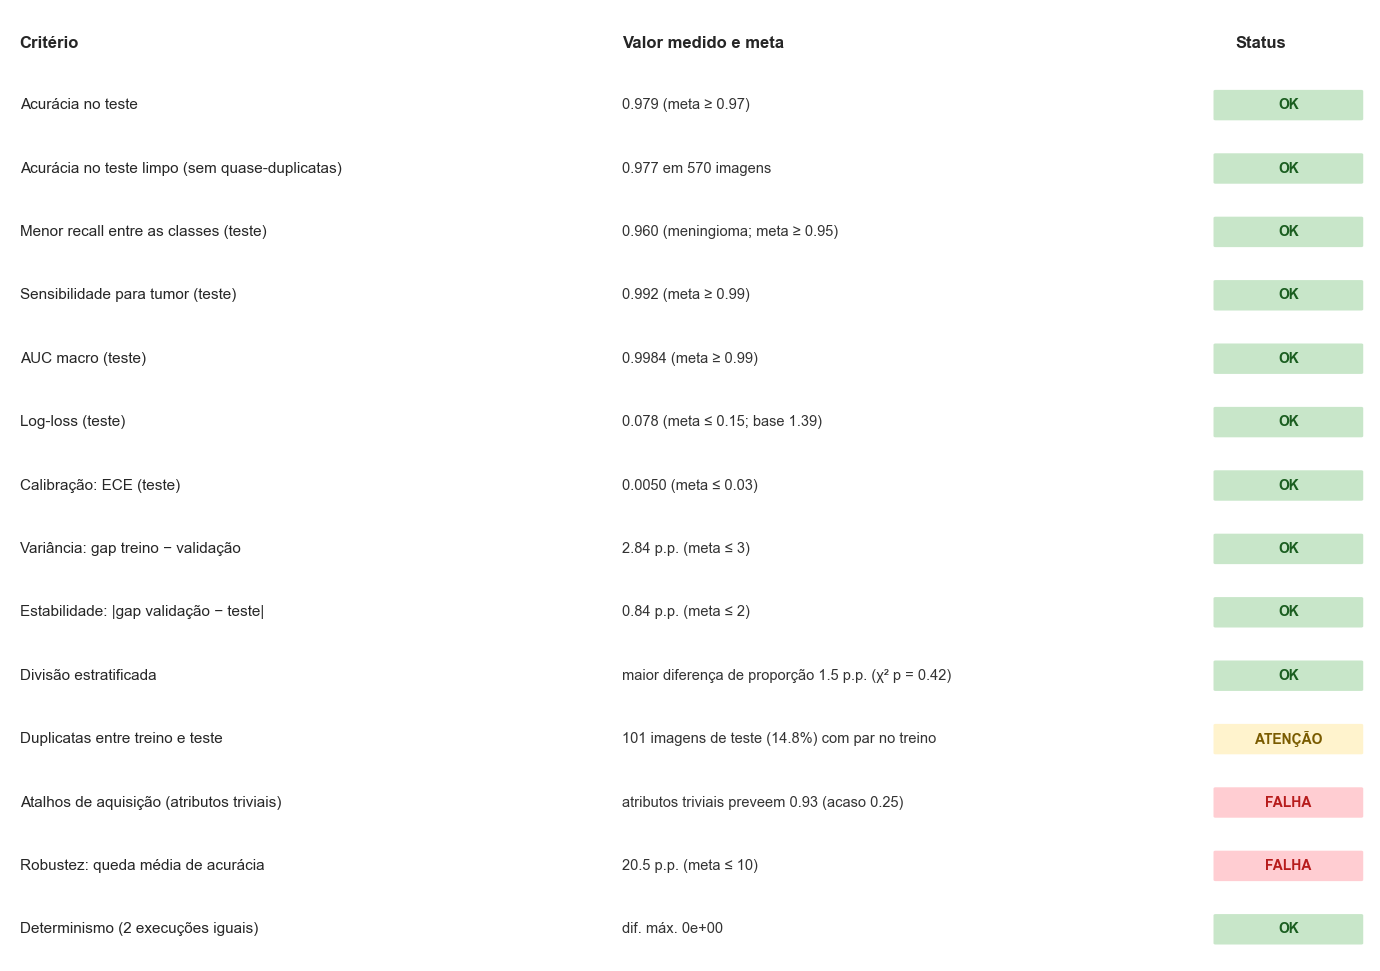

salvo: 18_checklist.png


In [21]:
def st(cond, aviso=False): return "ok" if cond else ("atencao" if aviso else "falha")
itens = [
 ("Acurácia no teste", st(acc("test") >= CRIT["acc_teste_min"]), f"{acc('test'):.3f} (meta ≥ {CRIT['acc_teste_min']})"),
 ("Acurácia no teste limpo (sem quase-duplicatas)", st(NUM["acc_teste_limpo"] >= CRIT["acc_teste_min"]), f"{NUM['acc_teste_limpo']:.3f} em {NUM['n_teste_limpo']} imagens"),
 ("Menor recall entre as classes (teste)", st(NUM["menor_recall_classe"] >= CRIT["recall_classe_min"]), f"{NUM['menor_recall_classe']:.3f} ({NUM['classe_menor_recall']}; meta ≥ {CRIT['recall_classe_min']})"),
 ("Sensibilidade para tumor (teste)", st(NUM["sensibilidade_tumor"] >= CRIT["sens_tumor_min"]), f"{NUM['sensibilidade_tumor']:.3f} (meta ≥ {CRIT['sens_tumor_min']})"),
 ("AUC macro (teste)", st(NUM["auc_macro_teste"] >= CRIT["auc_min"]), f"{NUM['auc_macro_teste']:.4f} (meta ≥ {CRIT['auc_min']})"),
 ("Log-loss (teste)", st(NUM["logloss_teste"] <= CRIT["logloss_max"]), f"{NUM['logloss_teste']:.3f} (meta ≤ {CRIT['logloss_max']}; base {NUM['logloss_prevalencia']:.2f})"),
 ("Calibração: ECE (teste)", st(NUM["ece_teste"] <= CRIT["ece_max"]), f"{NUM['ece_teste']:.4f} (meta ≤ {CRIT['ece_max']})"),
 ("Variância: gap treino − validação", st(g_tv <= CRIT["gap_treino_val_max"]), f"{100*g_tv:.2f} p.p. (meta ≤ {100*CRIT['gap_treino_val_max']:.0f})"),
 ("Estabilidade: |gap validação − teste|", st(abs(g_vt) <= CRIT["gap_val_teste_max"]), f"{100*abs(g_vt):.2f} p.p. (meta ≤ {100*CRIT['gap_val_teste_max']:.0f})"),
 ("Divisão estratificada", st(p_chi > .05, True), f"maior diferença de proporção {maxdev:.1f} p.p. (χ² p = {p_chi:.2f})"),
 ("Duplicatas entre treino e teste", st(dup_tt.mean() <= CRIT["duplicata_max"], True), f"{dup_tt.sum()} imagens de teste ({100*dup_tt.mean():.1f}%) com par no treino"),
 ("Atalhos de aquisição (atributos triviais)", st(acc_h <= CRIT["atalho_max"]), f"atributos triviais preveem {acc_h:.2f} (acaso {1/NC:.2f})"),
 ("Robustez: queda média de acurácia", st(qm <= CRIT["queda_robustez_max"]), f"{100*qm:.1f} p.p. (meta ≤ {100*CRIT['queda_robustez_max']:.0f})"),
 ("Determinismo (2 execuções iguais)", st(det <= 1e-5), f"dif. máx. {det:.0e}"),
]
(PASTA / "checklist.json").write_text(json.dumps([dict(item=i[0], status=i[1], evidencia=i[2]) for i in itens], ensure_ascii=False, indent=1), encoding="utf-8")
sty = {"ok": ("#c8e6c9", "#1b5e20", "OK"), "atencao": ("#fff3cd", "#7a5b00", "ATENÇÃO"), "falha": ("#ffcdd2", "#b71c1c", "FALHA")}
fig, ax = plt.subplots(figsize=(14, 0.6 * len(itens) + 1.5)); ax.axis("off"); ax.set_xlim(0, 14); ax.set_ylim(0, len(itens) + 1)
for x_, t_ in ((.1, "Critério"), (6.3, "Valor medido e meta"), (12.6, "Status")): ax.text(x_, len(itens) + .4, t_, fontweight="bold", fontsize=12)
for r_, (nome, s_, ev) in enumerate(itens):
    y = len(itens) - r_ - .5; fill, fg, rot = sty[s_]; ax.text(.1, y, nome, va="center", fontsize=11); ax.text(6.3, y, ev, va="center", fontsize=10.5, color="#333")
    ax.add_patch(mpatches.FancyBboxPatch((12.4, y - .22), 1.5, .44, boxstyle="round,pad=0.02", fc=fill, ec="none")); ax.text(13.15, y, rot, ha="center", va="center", fontsize=10, fontweight="bold", color=fg)
plt.tight_layout(); n_ok = sum(1 for i in itens if i[1] == "ok"); n_at = sum(1 for i in itens if i[1] == "atencao"); n_fa = sum(1 for i in itens if i[1] == "falha")
NUM.update(checklist_ok=n_ok, checklist_atencao=n_at, checklist_falha=n_fa, checklist_total=len(itens))
fora = "; ".join(f"{i[0]} ({'atenção' if i[1] == 'atencao' else 'falha'})" for i in itens if i[1] != "ok") or "nenhum"
salvar("18_checklist.png", "Checklist de aprovação",
       "Quatorze critérios (desempenho, generalização, calibração, integridade dos dados, atalhos, robustez e reprodutibilidade) com o valor medido, a meta e o status de cada um.",
       "Permite concluir objetivamente se o modelo está aprovado segundo critérios definidos antes de olhar o resultado. As metas são do grupo (dicionário CRIT) e podem ser ajustadas.",
       f"{n_ok} de {len(itens)} critérios OK, {n_at} com atenção e {n_fa} com falha. Fora do OK: {fora}.")

In [22]:
# ---- model card e exportações ----
card = f"""# Model card — {ALVO}

> Trabalho acadêmico. Não é um dispositivo médico e não deve apoiar diagnóstico real.

## Uso pretendido
Classificar imagens de ressonância magnética cerebral em 4 classes ({', '.join(CLASSES)}).

## Dados
- Conjunto Tumor Cerebral v1 (Roboflow, CC BY 4.0), {sum(len(DS[s]) for s in SPL3)} imagens 512×512: treino {len(DS['train'])}, validação {len(DS['val'])}, teste {len(DS['test'])}.
- {NUM['imagens_teste_quase_duplicata']} imagens de teste ({NUM['pct_teste_quase_duplicata']}%) têm quase-duplicata no treino; sem identificador de paciente.
- Manifesto do dataset (SHA-256): {manifest}

## Treino
""" + (f"- yolo11s-cls pré-treinado, {args_y.get('epochs')} épocas (máx.), AdamW, lr {args_y.get('lr0')}, batch {args_y.get('batch')}, imgsz {args_y.get('imgsz')}, semente {args_y.get('seed')}; {NUM['epocas']} épocas executadas, melhor na {NUM['melhor_epoca']}ª.\n" if EH_YOLO else f"- EfficientNet-B0 (torchvision, ImageNet), AdamW, lr 3e-4, batch 32, 512×512, semente 42; {NUM['epocas']} épocas, melhor na {NUM['melhor_epoca']}ª.\n") + f"""
## Desempenho (teste, {len(Y['test'])} imagens)
- Acurácia {NUM['acc_teste']:.4f} (IC 95% [{NUM['ic_acc_inf']:.4f}; {NUM['ic_acc_sup']:.4f}]) · F1 macro {NUM['f1_macro_teste']:.4f} · AUC macro {NUM['auc_macro_teste']:.4f} · log-loss {NUM['logloss_teste']:.4f} · ECE {NUM['ece_teste']:.4f}
- Teste limpo: acurácia {NUM['acc_teste_limpo']:.4f} ({NUM['n_teste_limpo']} imagens)
- Visão clínica: sensibilidade {NUM['sensibilidade_tumor']:.4f}, especificidade {NUM['especificidade']:.4f}
- Média ± desvio em 50 dobras do teste: {NUM['dobras_acc_media']:.4f} ± {NUM['dobras_acc_desvio']:.4f}
- Pior classe (recall): {NUM['classe_menor_recall']} = {NUM['menor_recall_classe']:.4f}
- Robustez: queda média de {NUM['queda_media_robustez_pp']:.1f} p.p. sob perturbações sintéticas

## Limitações
- Validação interna (mesmo conjunto de origem); sem validação externa.
- Quase-duplicatas entre treino e teste; auditoria de atalhos: atributos triviais da imagem preveem {NUM['acc_atalhos_teste']:.2f} (acaso {1/NC:.2f}).
- Uma execução de treino (sem variância entre treinos).

## Reprodutibilidade
- Pesos (SHA-256): {hash_w}
- Ambiente: Python {env['python']}, torch {env['torch']}, ultralytics {env['ultralytics']}, scikit-learn {env['scikit-learn']}; dispositivo {env['dispositivo']}. Diferença máxima entre execuções repetidas: {det:.0e}.
"""
(PASTA / "model_card.md").write_text(card, encoding="utf-8")
(PASTA / "legendas.json").write_text(json.dumps(sorted(LEG, key=lambda l: l["arquivo"]), ensure_ascii=False, indent=1), encoding="utf-8")
(PASTA / "tabelas.json").write_text(json.dumps(TABS, ensure_ascii=False), encoding="utf-8")
nums = pd.DataFrame({"valor": pd.Series(NUM)}); nums.to_csv(PASTA / "numeros_chave.csv", encoding="utf-8-sig"); (PASTA / "numeros_chave.json").write_text(json.dumps(NUM, ensure_ascii=False, default=str), encoding="utf-8")
print(f"\n{len(LEG)} figuras em {FIG}"); [print(" -", l["arquivo"]) for l in sorted(LEG, key=lambda l: l["arquivo"])]


18 figuras em C:\Users\pedro.almeida\Downloads\Trabalho Faculdade\Validacoes\01_YOLO11s-cls\figuras
 - 01_dados.png
 - 02_vazamento_duplicatas.png
 - 03_auditoria_atalhos.png
 - 04_treinamento.png
 - 05_acuracia_por_epoca.png
 - 06_desempenho_variancia.png
 - 07_matrizes_confusao.png
 - 08_relatorio_classificacao.png
 - 09_roc_pr.png
 - 10_log_loss.png
 - 11_calibracao.png
 - 12_visao_clinica.png
 - 13_incerteza.png
 - 14_robustez.png
 - 15_gradcam_acertos.png
 - 16_gradcam_erros.png
 - 17_galeria_erros.png
 - 18_checklist.png


[None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None]